#                                               **TP3  Segmentation d'images**

### **Elaboré par :** Ayeb Farah

### **Filière :** RT4

## **I. Importer les librairies et bibliothéques nécessaires**

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import cv2
from skimage.io import imread, imshow
from skimage.filters import threshold_otsu,threshold_multiotsu
from skimage.transform import resize
from sklearn.cluster import KMeans
from google.colab import drive
drive.mount('/content/drive')
from scipy import ndimage
from collections import deque


Mounted at /content/drive


# **I-1. Chargement et affichage des images de test**


**Charger et afficher les images de test (feuille, outil, mandrill).**





In [3]:
feuille = cv2.imread('feuille.png', cv2.IMREAD_GRAYSCALE)
outil = cv2.imread('outil.png', cv2.IMREAD_GRAYSCALE)
mandrill = cv2.imread('mandrillgray.jpg', cv2.IMREAD_GRAYSCALE)

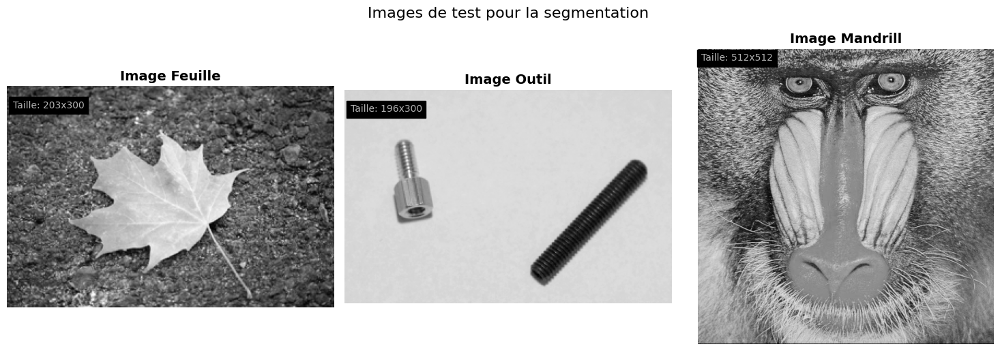

In [4]:
# Affichage des images
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Image Feuille
axes[0].imshow(feuille, cmap='gray')
axes[0].set_title('Image Feuille', fontsize=14, fontweight='bold')
axes[0].axis('off')
# Ajout d'informations sur l'image
axes[0].text(5, 20, f'Taille: {feuille.shape[0]}x{feuille.shape[1]}',
             color='white', fontsize=10, backgroundcolor='black', alpha=0.7)

# Image Outil
axes[1].imshow(outil, cmap='gray')
axes[1].set_title('Image Outil', fontsize=14, fontweight='bold')
axes[1].axis('off')
axes[1].text(5, 20, f'Taille: {outil.shape[0]}x{outil.shape[1]}',
             color='white', fontsize=10, backgroundcolor='black', alpha=0.7)

# Image Mandrill
axes[2].imshow(mandrill, cmap='gray')
axes[2].set_title('Image Mandrill', fontsize=14, fontweight='bold')
axes[2].axis('off')
axes[2].text(5, 20, f'Taille: {mandrill.shape[0]}x{mandrill.shape[1]}',
             color='white', fontsize=10, backgroundcolor='black', alpha=0.7)

plt.suptitle('Images de test pour la segmentation', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# I-2. **Prétraitement des images**

**1. Afficher les histogrammes des images de test et
si nécessaire appliquer une méthode d'amélioration de constraste (exemple: CLAHE)**

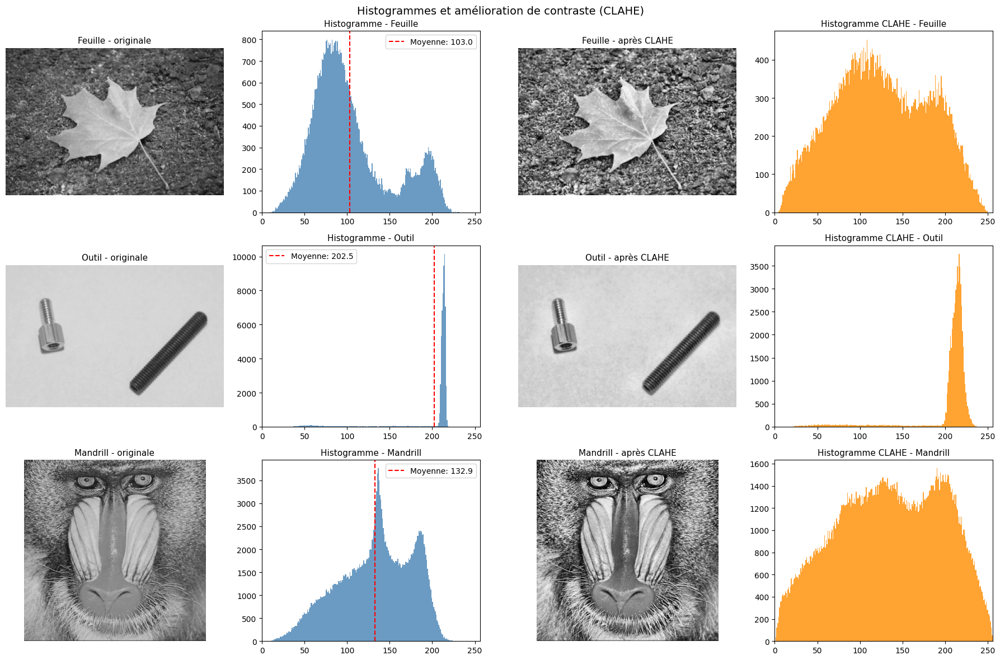

In [5]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
images   = [('Feuille', feuille), ('Outil', outil), ('Mandrill', mandrill)]
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
fig.suptitle('Histogrammes et amélioration de contraste (CLAHE)', fontsize=14)

for row, (name, img) in enumerate(images):
    img_clahe = clahe.apply(img)
    cv2.imwrite(f'{name}_clahe.png', img_clahe)
    axes[row, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[row, 0].set_title(f'{name} - originale', fontsize=11)
    axes[row, 0].axis('off')

    axes[row, 1].hist(img.ravel(), bins=256, range=(0, 256), color='steelblue', alpha=0.8)
    axes[row, 1].set_title(f'Histogramme - {name}', fontsize=11)
    axes[row, 1].set_xlim([0, 256])

    # Ajout d'une ligne pour la moyenne
    moyenne = img.mean()
    axes[row, 1].axvline(moyenne, color='red', linestyle='--', label=f'Moyenne: {moyenne:.1f}')
    axes[row, 1].legend()

    axes[row, 2].imshow(img_clahe, cmap='gray', vmin=0, vmax=255)
    axes[row, 2].set_title(f'{name} - après CLAHE', fontsize=11)
    axes[row, 2].axis('off')

    axes[row, 3].hist(img_clahe.ravel(), bins=256, range=(0, 256), color='darkorange', alpha=0.8)
    axes[row, 3].set_title(f'Histogramme CLAHE - {name}', fontsize=11)
    axes[row, 3].set_xlim([0, 256])

plt.tight_layout()
plt.show()

In [6]:
print("Caractéristique des images")
images_info = {
    'Feuille': feuille,
    'Outil': outil,
    'Mandrill': mandrill
}

for name, img in images_info.items():
    print(f"\n{name}:")
    print(f"  - Dimensions: {img.shape}")
    print(f"  - Type de données: {img.dtype}")
    print(f"  - Intensité min: {img.min()}")
    print(f"  - Intensité max: {img.max()}")
    print(f"  - Intensité moyenne: {img.mean():.2f}")
    print(f"  - Écart-type: {img.std():.2f}")

Caractéristique des images

Feuille:
  - Dimensions: (203, 300)
  - Type de données: uint8
  - Intensité min: 9
  - Intensité max: 231
  - Intensité moyenne: 103.05
  - Écart-type: 45.83

Outil:
  - Dimensions: (196, 300)
  - Type de données: uint8
  - Intensité min: 29
  - Intensité max: 245
  - Intensité moyenne: 202.53
  - Écart-type: 34.83

Mandrill:
  - Dimensions: (512, 512)
  - Type de données: uint8
  - Intensité min: 8
  - Intensité max: 241
  - Intensité moyenne: 132.94
  - Écart-type: 42.85


**2. Appliquer des filtres de lissage pour réduire le bruit et comparer les résultats entre un filtrage gaussien et un filtrage moyenneur.**

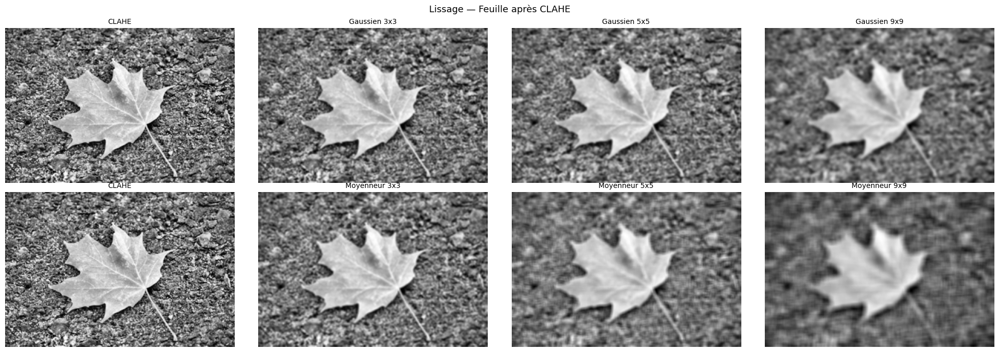

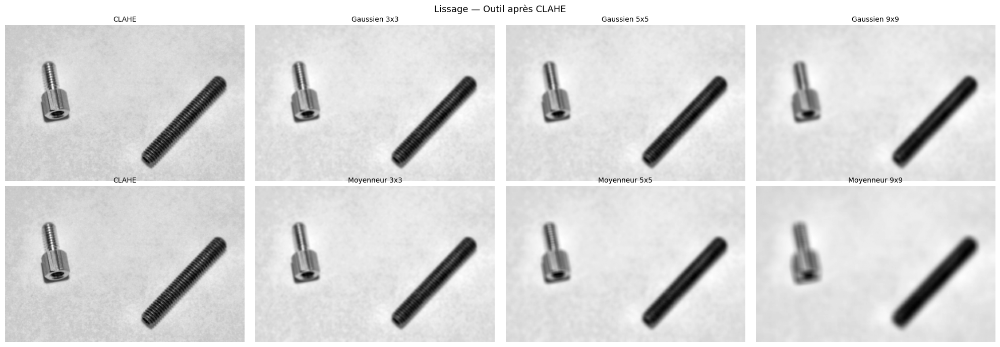

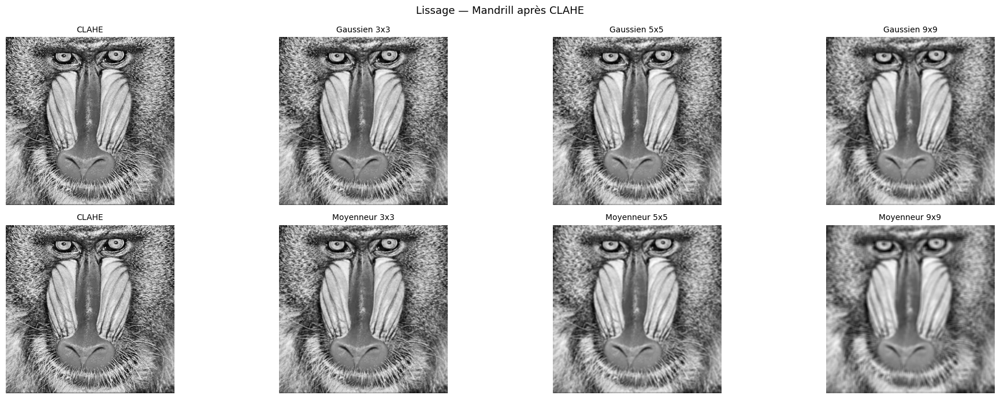

In [7]:
feuille_clahe = cv2.imread('Feuille_clahe.png', cv2.IMREAD_GRAYSCALE)
outil_clahe = cv2.imread('Outil_clahe.png', cv2.IMREAD_GRAYSCALE)
mandrill_clahe = cv2.imread('Mandrill_clahe.png', cv2.IMREAD_GRAYSCALE)
images = [
    ('Feuille', feuille_clahe),
    ('Outil', outil_clahe),
    ('Mandrill', mandrill_clahe)
]

kernel_sizes = [3, 5, 9]

for name, img in images:
    fig, axes = plt.subplots(2, len(kernel_sizes) + 1, figsize=(20, 7))
    fig.suptitle(f'Lissage — {name} après CLAHE', fontsize=13)

    for r in range(2):
        axes[r, 0].imshow(img, cmap='gray')
        axes[r, 0].set_title('CLAHE', fontsize=10)
        axes[r, 0].axis('off')

    for col, k in enumerate(kernel_sizes, start=1):
        gauss = cv2.GaussianBlur(img, (k, k), sigmaX=0)
        moyen = cv2.blur(img, (k, k))

        axes[0, col].imshow(gauss, cmap='gray')
        axes[0, col].set_title(f'Gaussien {k}x{k}', fontsize=10)
        axes[0, col].axis('off')

        axes[1, col].imshow(moyen, cmap='gray')
        axes[1, col].set_title(f'Moyenneur {k}x{k}', fontsize=10)
        axes[1, col].axis('off')

    axes[0, 0].set_ylabel('Gaussien', fontsize=10)
    axes[1, 0].set_ylabel('Moyenneur', fontsize=10)

    plt.tight_layout()
    plt.show()

* **Filtre Gaussien :** Produit un flou plus doux, particulièrement perceptible avec des tailles de noyau plus grandes. Il a tendance à mieux préserver les contours que le filtre Moyenneur tout en réduisant le bruit.

* **Filtre Moyenneur (Moyenne) :** Entraîne un flou plus uniforme, ce qui peut parfois rendre les contours moins nets par rapport au filtre Gaussien. Il réduit efficacement le bruit de type « sel et poivre » mais peut aussi estomper les détails fins.

* **Impact de la taille du noyau :** À mesure que la taille du noyau augmente pour les deux filtres, les images deviennent progressivement plus floues, indiquant une réduction du bruit plus agressive mais aussi une plus grande perte de détails de l'image.

**3. Afficher les gradients de l'image *outil.png* à l'aide de la méthode de Sobel et observer les cartes de contour obtenues.**

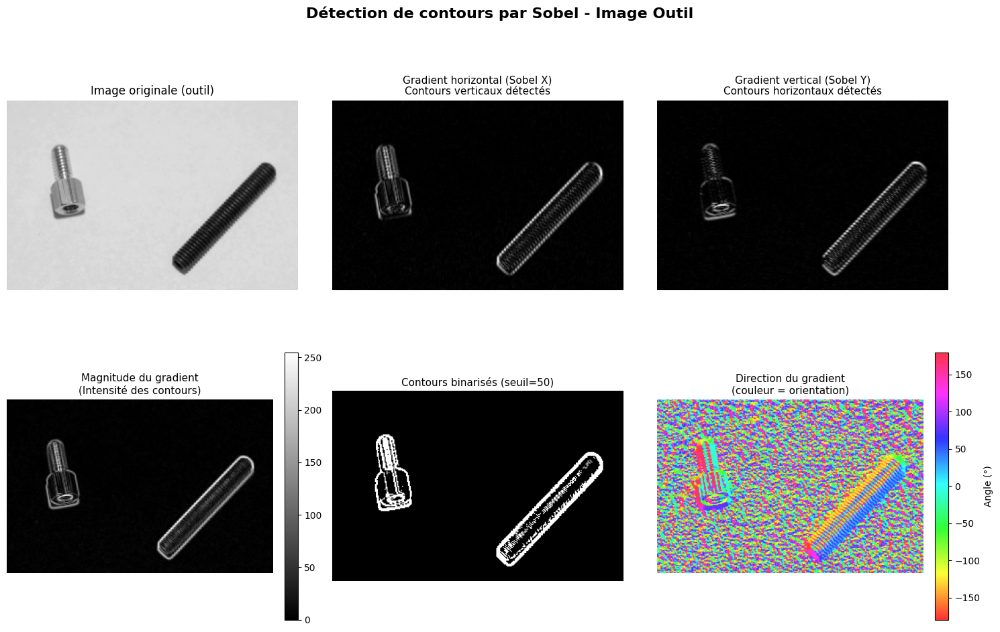

ANALYSE STATISTIQUE DES GRADIENTS (Sobel)
Gradient X - Moyenne: 13.05, Max: 468.00
Gradient Y - Moyenne: 11.93, Max: 482.00
Magnitude - Moyenne: 9.08, Max: 255.00


In [8]:
# Application du filtre de Sobel
# Gradient selon X (horizontal)
sobel_x = cv2.Sobel(outil, cv2.CV_64F, 1, 0, ksize=3)
# Gradient selon Y (vertical)
sobel_y = cv2.Sobel(outil, cv2.CV_64F, 0, 1, ksize=3)

# Calcul de la magnitude (intensité du gradient)
sobel_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)
# Normalisation pour affichage (entre 0 et 255)
sobel_magnitude = cv2.normalize(sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Calcul de la direction du gradient (optionnel)
sobel_direction = np.arctan2(sobel_y, sobel_x) * 180 / np.pi

# Affichage des résultats
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Détection de contours par Sobel - Image Outil', fontsize=16, fontweight='bold')

# Image originale
axes[0, 0].imshow(outil, cmap='gray')
axes[0, 0].set_title('Image originale (outil)', fontsize=12)
axes[0, 0].axis('off')

# Gradient X
axes[0, 1].imshow(np.abs(sobel_x), cmap='gray')
axes[0, 1].set_title('Gradient horizontal (Sobel X)\nContours verticaux détectés', fontsize=11)
axes[0, 1].axis('off')

# Gradient Y
axes[0, 2].imshow(np.abs(sobel_y), cmap='gray')
axes[0, 2].set_title('Gradient vertical (Sobel Y)\nContours horizontaux détectés', fontsize=11)
axes[0, 2].axis('off')

# Magnitude du gradient
im = axes[1, 0].imshow(sobel_magnitude, cmap='gray')
axes[1, 0].set_title('Magnitude du gradient\n(Intensité des contours)', fontsize=11)
axes[1, 0].axis('off')
plt.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

# Seuillage de la magnitude pour mieux visualiser les contours
seuil = 50  # À ajuster selon les résultats
contours_seuilles = (sobel_magnitude > seuil).astype(np.uint8) * 255
axes[1, 1].imshow(contours_seuilles, cmap='gray')
axes[1, 1].set_title(f'Contours binarisés (seuil={seuil})', fontsize=11)
axes[1, 1].axis('off')

# Direction du gradient (en fausses couleurs)
im2 = axes[1, 2].imshow(sobel_direction, cmap='hsv', alpha=0.8)
axes[1, 2].set_title('Direction du gradient\n(couleur = orientation)', fontsize=11)
axes[1, 2].axis('off')
plt.colorbar(im2, ax=axes[1, 2], fraction=0.046, pad=0.04, label='Angle (°)')

plt.tight_layout()
plt.show()

# Affichage des statistiques
print("=" * 60)
print("ANALYSE STATISTIQUE DES GRADIENTS (Sobel)")
print("=" * 60)
print(f"Gradient X - Moyenne: {np.mean(np.abs(sobel_x)):.2f}, Max: {np.max(np.abs(sobel_x)):.2f}")
print(f"Gradient Y - Moyenne: {np.mean(np.abs(sobel_y)):.2f}, Max: {np.max(np.abs(sobel_y)):.2f}")
print(f"Magnitude - Moyenne: {np.mean(sobel_magnitude):.2f}, Max: {np.max(sobel_magnitude):.2f}")

Les résultats de l’opérateur de Sobel montrent que l’image de l’outil présente des contours bien définis dans les deux directions (horizontale et verticale), avec des valeurs maximales élevées indiquant des transitions d’intensité importantes. Les moyennes faibles des gradients suggèrent que la majorité des pixels appartient à des régions homogènes, tandis que la magnitude du gradient met en évidence quelques contours dominants correspondant aux bords de l’objet.

**4. Appliquez un seuillage sur les gradients pour obtenir une première détection de contours et comparer avec le détecteur de Canny.**

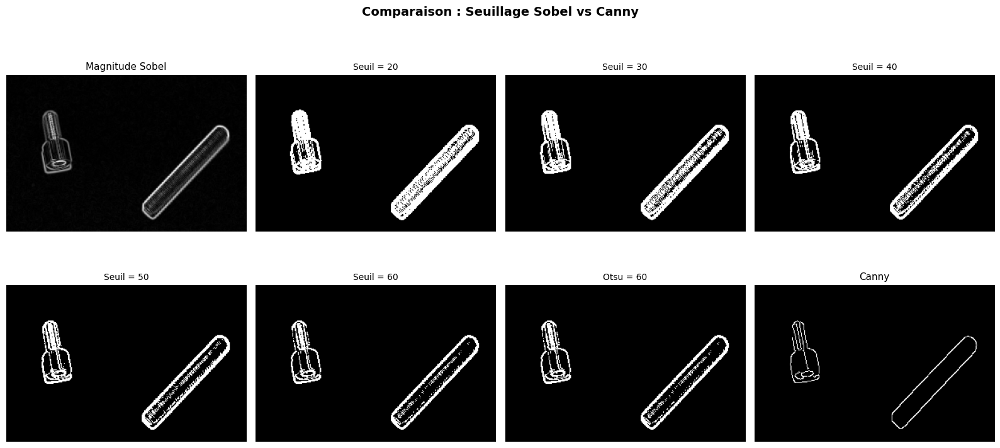

In [9]:
# Liste des seuils
seuils = [20, 30, 40, 50, 60, 80]

# CANNY (à ajouter pour comparaison)
outil_flou = cv2.GaussianBlur(outil, (5, 5), 1.4)
canny = cv2.Canny(outil_flou, 50, 150)

# Figure
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Comparaison : Seuillage Sobel vs Canny', fontsize=14, fontweight='bold')

# Magnitude originale
axes[0, 0].imshow(sobel_magnitude, cmap='gray')
axes[0, 0].set_title('Magnitude Sobel', fontsize=11)
axes[0, 0].axis('off')

# Différents seuils Sobel
for i, s in enumerate(seuils):
    row = (i + 1) // 4
    col = (i + 1) % 4

    binaire = (sobel_magnitude > s).astype(np.uint8) * 255

    axes[row, col].imshow(binaire, cmap='gray')
    axes[row, col].set_title(f'Seuil = {s}', fontsize=10)
    axes[row, col].axis('off')

# OTSU
seuil_otsu_val, seuil_otsu_img = cv2.threshold(
    sobel_magnitude, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

axes[1, 2].imshow(seuil_otsu_img, cmap='gray')
axes[1, 2].set_title(f'Otsu = {seuil_otsu_val:.0f}', fontsize=10)
axes[1, 2].axis('off')

# CANNY (comparaison directe)
axes[1, 3].imshow(canny, cmap='gray')
axes[1, 3].set_title('Canny', fontsize=11)
axes[1, 3].axis('off')

plt.tight_layout()
plt.show()

- **Influence du seuil sur Sobel**

L’analyse des différents seuils montre que le résultat du seuillage de la magnitude du gradient dépend fortement de la valeur choisie.

Un seuil faible (20–30) entraîne une détection excessive de contours, incluant beaucoup de bruit.
Un seuil intermédiaire (40–60) permet de mieux isoler les contours principaux.
Un seuil élevé (80+) supprime une grande partie des contours, y compris des informations importantes.


- **Seuillage automatique (Otsu)**

La méthode d’Otsu permet de déterminer automatiquement un seuil optimal basé sur l’histogramme de l’image. Cependant, appliquée à la magnitude de Sobel, elle reste limitée car elle ne prend pas en compte la structure spatiale des contours.


- **Comparaison avec Canny**

Le détecteur de Canny fournit des contours plus fins, continus et moins bruités que le seuillage de Sobel. Contrairement à Sobel, Canny utilise plusieurs étapes (filtrage, suppression des non-maxima et hystérésis) qui améliorent considérablement la qualité des contours.
Ainsi, même avec un seuillage optimisé, Sobel reste moins performant que Canny.

In [10]:
print("\nAnalyse du nombre de pixels détectés :")

for s in seuils:
    binaire = (sobel_magnitude > s).astype(np.uint8)
    print(f"Seuil {s} -> pixels contours : {np.sum(binaire)}")

print(f"Canny -> pixels contours : {np.sum(canny > 0)}")


Analyse du nombre de pixels détectés :
Seuil 20 -> pixels contours : 5087
Seuil 30 -> pixels contours : 4305
Seuil 40 -> pixels contours : 3559
Seuil 50 -> pixels contours : 2897
Seuil 60 -> pixels contours : 2380
Seuil 80 -> pixels contours : 1659
Canny -> pixels contours : 824


On observe que Sobel détecte plus de pixels contours que Canny, ce qui indique une sensibilité plus élevée au bruit.

**5. Utilisez la transformée de Hough pour affichez les lignes les plus importantes de cette image.**

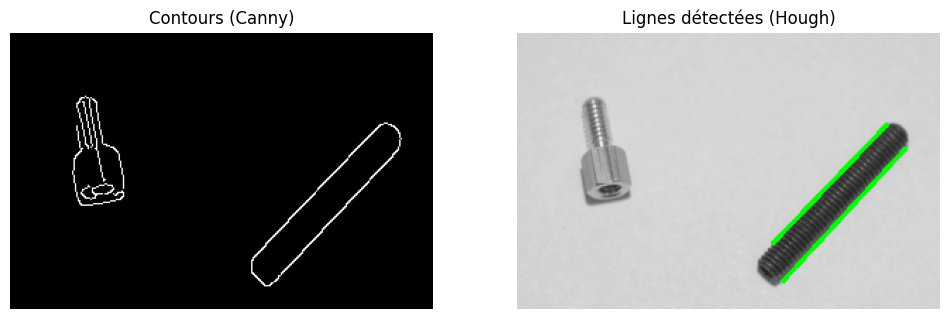

Nombre de lignes détectées : 2


In [11]:
edges = cv2.Canny(outil_flou, 50, 150)
lines = cv2.HoughLinesP(
    edges,
    rho=1,
    theta=np.pi/180,
    threshold=100,
    minLineLength=50,
    maxLineGap=10
)

image_lignes = cv2.cvtColor(outil, cv2.COLOR_GRAY2BGR)

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(image_lignes, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.title("Contours (Canny)")
plt.imshow(edges, cmap='gray')
plt.axis('off')

plt.subplot(1,2,2)
plt.title("Lignes détectées (Hough)")
plt.imshow(image_lignes)
plt.axis('off')

plt.show()

if lines is not None:
    print(f"Nombre de lignes détectées : {len(lines)}")
else:
    print("Aucune ligne détectée")

La transformée de Hough a été appliquée sur les contours détectés par l’algorithme de Canny afin d’identifier les lignes présentes dans l’image. Cette méthode permet de détecter automatiquement les structures linéaires en transformant les points de contours dans un espace paramétrique.

In [12]:
for t in [50, 100, 150]:
    lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=t,
                            minLineLength=50, maxLineGap=10)
    print(f"Threshold {t} → lignes détectées : {0 if lines is None else len(lines)}")

Threshold 50 → lignes détectées : 3
Threshold 100 → lignes détectées : 2
Threshold 150 → lignes détectées : 0


On observe que l’augmentation du seuil réduit le nombre de lignes détectées, permettant de conserver uniquement les structures principales.

# **I-3. Méthodes de segmentation**

## **I.3.1. Segmentation par seuillage**

**1. Lire l’image de test *feuille.png*,  puis afficher-là.**

**2. Afficher son histogramme. Identifier visuellement les zones séparables sur l'histogramme.**


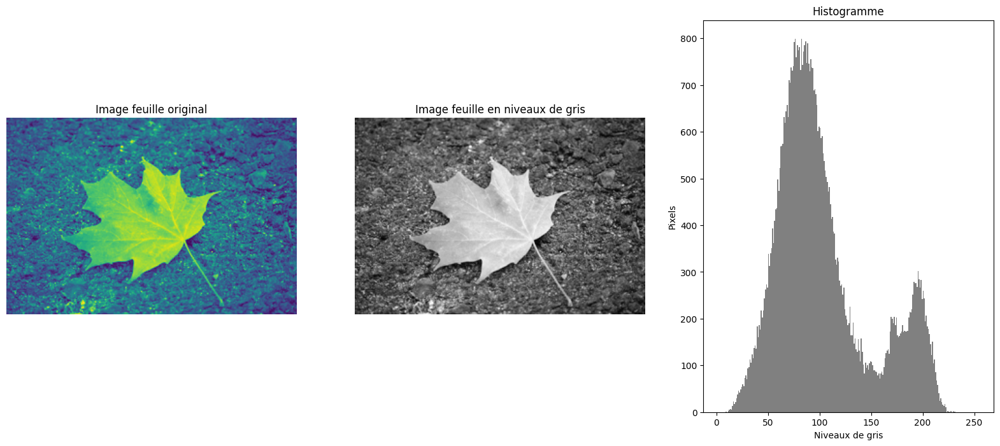

In [13]:
plt.figure(figsize=(20,8))

plt.subplot(1,3,1)
plt.imshow(feuille)
plt.title("Image feuille original")
plt.axis('off')
plt.subplot(1,3,2)
plt.imshow(feuille, cmap='gray')
plt.title("Image feuille en niveaux de gris")
plt.axis('off')

plt.subplot(1,3,3)
plt.hist(feuille.ravel(), bins=256, range=(0,256), color='gray')
plt.title("Histogramme")
plt.xlabel("Niveaux de gris")
plt.ylabel("Pixels")

plt.show()

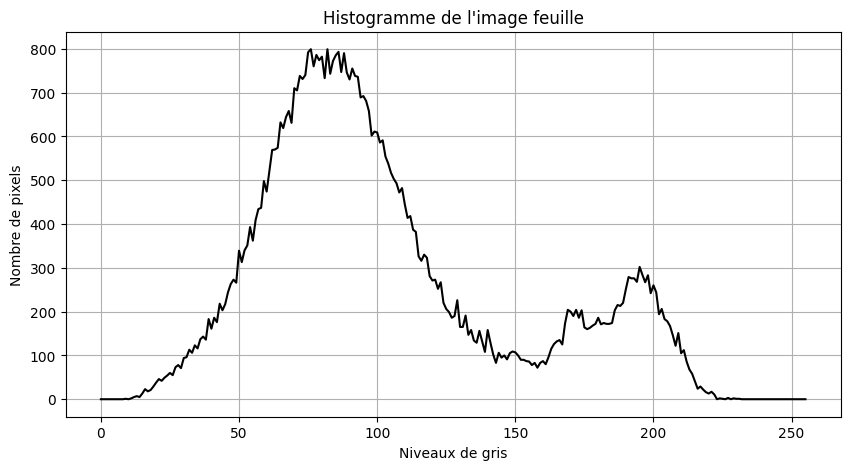

ANALYSE NUMÉRIQUE DE L'HISTOGRAMME
Intensité minimale : 9
Intensité maximale : 231
Moyenne : 103.05
Ecart-type : 45.83

Pics principaux (intensités dominantes) :
 - Intensité 76 avec 799 pixels
 - Intensité 82 avec 799 pixels


In [14]:
hist, bins = np.histogram(feuille.flatten(), bins=256, range=[0,256])

# Affichage graphique
plt.figure(figsize=(10,5))
plt.plot(hist, color='black')
plt.title("Histogramme de l'image feuille")
plt.xlabel("Niveaux de gris")
plt.ylabel("Nombre de pixels")
plt.grid()
plt.show()

# Affichage des valeurs importantes
print("="*60)
print("ANALYSE NUMÉRIQUE DE L'HISTOGRAMME")
print("="*60)

print(f"Intensité minimale : {feuille.min()}")
print(f"Intensité maximale : {feuille.max()}")
print(f"Moyenne : {feuille.mean():.2f}")
print(f"Ecart-type : {feuille.std():.2f}")

# Trouver les pics principaux
# On prend les 2 plus grandes valeurs de l'histogramme
indices_pics = np.argsort(hist)[-2:]

print("\nPics principaux (intensités dominantes) :")
for idx in indices_pics:
    print(f" - Intensité {idx} avec {hist[idx]} pixels")

L’histogramme présente deux pics bien distincts correspondant au fond et à la feuille. Cela indique que l’image est bimodale et donc adaptée à une segmentation par seuillage. Un seuil choisi entre ces deux pics permet de séparer efficacement les deux régions.

**3. Calculer manuellement un seuil de segmentation et segmenter l'image. Afficher le résultat de segmentation.**

Ce code nous permet de connaitre les coordonnées exactes des deux pics pour calculer le seuil manuellement.

In [15]:
from scipy.signal import find_peaks

hist, bins = np.histogram(feuille.ravel(), bins=256, range=(0,256))

# détection des pics locaux
peaks, _ = find_peaks(hist, distance=20)

# trier les pics par importance
sorted_peaks = peaks[np.argsort(hist[peaks])[::-1]]

print("PICS DETECTÉS :")
for i in range(min(5, len(sorted_peaks))):
    p = sorted_peaks[i]
    print(f"Pic {i+1} -> Intensité = {p}, Valeur = {hist[p]}")

PICS DETECTÉS :
Pic 1 -> Intensité = 82, Valeur = 799
Pic 2 -> Intensité = 102, Valeur = 591
Pic 3 -> Intensité = 59, Valeur = 498
Pic 4 -> Intensité = 195, Valeur = 302
Pic 5 -> Intensité = 123, Valeur = 267


Le seuil manuelle calculé est donc : **T = (195+82​) / 2 ≈ 139**

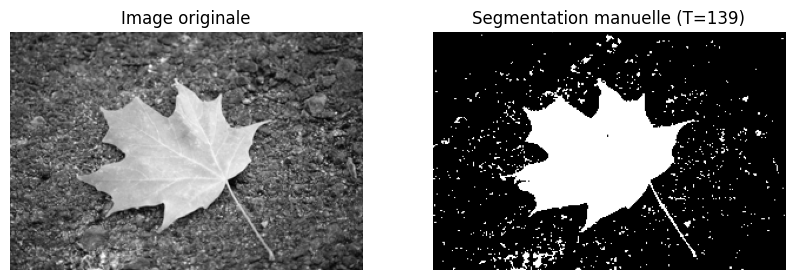

In [16]:
seuil_manuel = 139

# Application du seuillage
_, segmentation_manuel = cv2.threshold(
    feuille,
    seuil_manuel,
    255,
    cv2.THRESH_BINARY
)

# Affichage
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(feuille, cmap='gray')
plt.title("Image originale")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(segmentation_manuel, cmap='gray')
plt.title(f"Segmentation manuelle (T={seuil_manuel})")
plt.axis('off')

plt.show()

Un seuil de segmentation a été choisi manuellement en se basant sur l’analyse de l’histogramme de l’image. Ce seuil correspond à une valeur située entre les deux pics principaux représentant le fond et l’objet.

L’application de ce seuil permet de transformer l’image en une image binaire, où les pixels appartenant à la feuille sont séparés du fond. Les pixels ayant une intensité supérieure au seuil sont classés dans une classe, tandis que les autres appartiennent à l’autre classe.

Le résultat obtenu montre une bonne séparation entre la feuille et le fond, ce qui confirme que le choix du seuil est pertinent.

**4. Calculer le seuil avec la méthode d’Otsu et affichez le résultat de la segmentation. Comparer avec le seuillage manuel.**

Seuil calculé par Otsu : 129.00
Seuil manuel choisi : 139


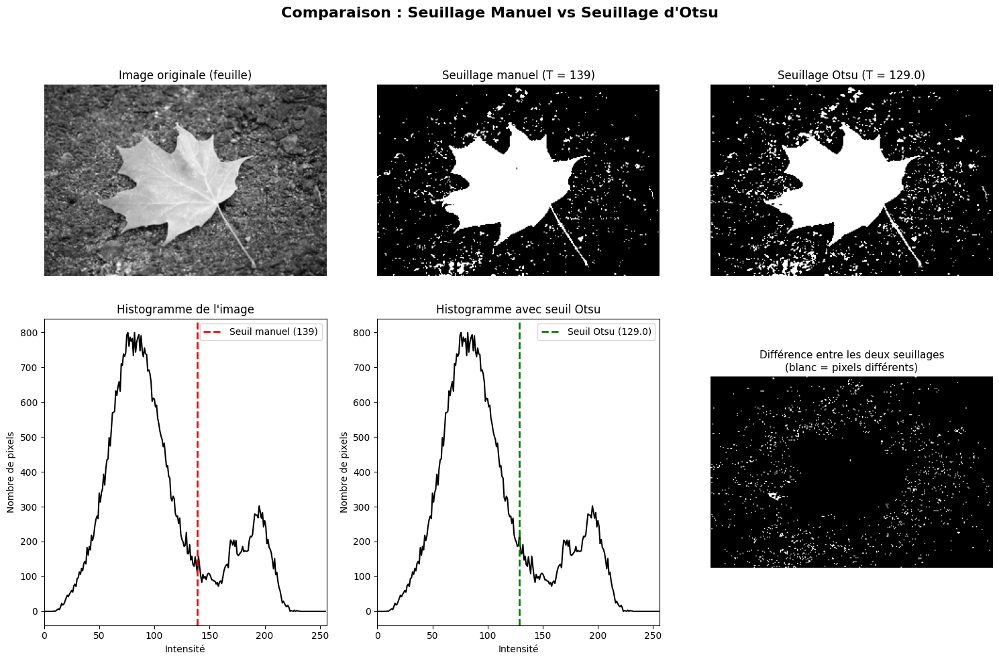

In [17]:
seuil_otsu, segmentation_otsu = cv2.threshold(
    feuille,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU  # Otsu + binarisation
)

# Affichage du seuil trouvé
print(f"Seuil calculé par Otsu : {seuil_otsu:.2f}")
print(f"Seuil manuel choisi : {seuil_manuel}")
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Comparaison : Seuillage Manuel vs Seuillage d\'Otsu', fontsize=16, fontweight='bold')

axes[0, 0].imshow(feuille, cmap='gray')
axes[0, 0].set_title('Image originale (feuille)', fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(segmentation_manuel, cmap='gray')
axes[0, 1].set_title(f'Seuillage manuel (T = {seuil_manuel})', fontsize=12)
axes[0, 1].axis('off')

axes[0, 2].imshow(segmentation_otsu, cmap='gray')
axes[0, 2].set_title(f'Seuillage Otsu (T = {seuil_otsu:.1f})', fontsize=12)
axes[0, 2].axis('off')

hist = cv2.calcHist([feuille], [0], None, [256], [0, 256])

axes[1, 0].plot(hist, color='black')
axes[1, 0].set_title('Histogramme de l\'image', fontsize=12)
axes[1, 0].set_xlabel('Intensité')
axes[1, 0].set_ylabel('Nombre de pixels')
axes[1, 0].set_xlim([0, 256])
axes[1, 0].axvline(seuil_manuel, color='red', linestyle='--', linewidth=2, label=f'Seuil manuel ({seuil_manuel})')
axes[1, 0].legend()

axes[1, 1].plot(hist, color='black')
axes[1, 1].set_title('Histogramme avec seuil Otsu', fontsize=12)
axes[1, 1].set_xlabel('Intensité')
axes[1, 1].set_ylabel('Nombre de pixels')
axes[1, 1].set_xlim([0, 256])
axes[1, 1].axvline(seuil_otsu, color='green', linestyle='--', linewidth=2, label=f'Seuil Otsu ({seuil_otsu:.1f})')
axes[1, 1].legend()

# Comparaison directe des deux segmentations
# Calcul de la différence entre les deux segmentations
difference = cv2.absdiff(segmentation_manuel, segmentation_otsu)
axes[1, 2].imshow(difference, cmap='gray')
axes[1, 2].set_title('Différence entre les deux seuillages\n(blanc = pixels différents)', fontsize=11)
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()


🔹 **Seuillage manuel**

Un seuil a été choisi manuellement en se basant sur l’histogramme, entre les deux pics principaux. Ce seuillage permet de séparer correctement la feuille du fond, bien que le choix du seuil reste dépendant de l’observation visuelle et donc subjectif.

🔹 **Seuillage d’Otsu**

La méthode d’Otsu calcule automatiquement un seuil optimal en maximisant la variance inter-classes. Le résultat obtenu est comparable, voire meilleur que le seuillage manuel, car il repose sur une approche statistique objective.

🔹 **Comparaison**

Les résultats montrent que :

le seuillage manuel peut être efficace si le seuil est bien choisi
la méthode d’Otsu permet d’obtenir un résultat similaire sans intervention humaine

Dans ce cas, les deux méthodes donnent des résultats proches car l’image présente une séparation claire entre les classes.

In [18]:
def analyser_segmentation(img_seg, nom):
    n_objet = np.sum(img_seg == 255)  # Pixels de l'objet (blanc)
    n_fond = np.sum(img_seg == 0)      # Pixels du fond (noir)
    ratio_objet = n_objet / img_seg.size * 100

    print(f"\n{nom}:")
    print(f"  - Pixels objet (blanc): {n_objet}")
    print(f"  - Pixels fond (noir): {n_fond}")
    print(f"  - Ratio objet/fond: {ratio_objet:.2f}% / {100-ratio_objet:.2f}%")

print("=" * 60)
print("ANALYSE STATISTIQUE DES SEGMENTATIONS")
print("=" * 60)

analyser_segmentation(segmentation_manuel, "Seuillage manuel (T=140)")
analyser_segmentation(segmentation_otsu, f"Seuillage Otsu (T={seuil_otsu:.1f})")

ANALYSE STATISTIQUE DES SEGMENTATIONS

Seuillage manuel (T=140):
  - Pixels objet (blanc): 12128
  - Pixels fond (noir): 48772
  - Ratio objet/fond: 19.91% / 80.09%

Seuillage Otsu (T=129.0):
  - Pixels objet (blanc): 13613
  - Pixels fond (noir): 47287
  - Ratio objet/fond: 22.35% / 77.65%


Le seuillage manuel (T=140) isole moins de pixels objet (19,66%) que la méthode d'Otsu (T=129) qui en détecte davantage (22,35%), ce qui signifie qu'Otsu segmente une région de feuille légèrement plus large en abaissant le seuil de 11 niveaux de gris.

## **I.3.2. Segmentation par kmeans**

**1.  Lire l’image de test *outil.png* et appliquer l’algorithme des k-means pour segmenter l'image**




In [19]:
outil_color = cv2.imread('outil.png')  # Version couleur pour K-means
outil_color = cv2.cvtColor(outil_color, cv2.COLOR_BGR2RGB)
print(f"Dimensions de l'image: {outil.shape}")
print(f"Valeurs d'intensité: min={outil.min()}, max={outil.max()}, moyenne={outil.mean():.2f}")

Dimensions de l'image: (196, 300)
Valeurs d'intensité: min=29, max=245, moyenne=202.53


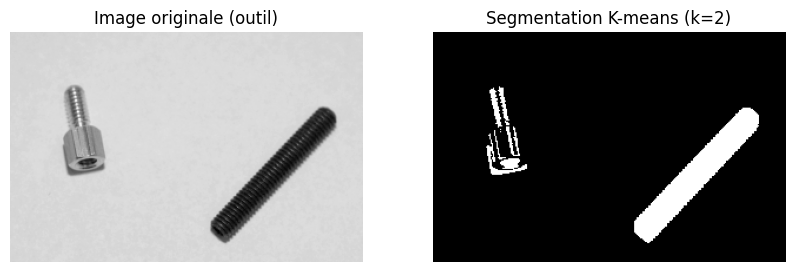

In [20]:
pixels = outil.reshape(-1, 1)  # transformer en vecteur (N,1)

# --- Application K-means ---
k = 2  # nombre de classes (objet + fond)
kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
kmeans.fit(pixels)

# --- Résultat ---
labels = kmeans.labels_
segmented = labels.reshape(outil.shape)

# normalisation pour affichage (0 et 255)
segmented = (segmented * (255 // (k-1))).astype(np.uint8)

# --- Affichage ---
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(outil, cmap='gray')
plt.title("Image originale (outil)")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(segmented, cmap='gray')
plt.title(f"Segmentation K-means (k={k})")
plt.axis('off')

plt.show()

* L’algorithme K-means permet de regrouper les pixels en classes homogènes en fonction de leur intensité. Chaque pixel est assigné au cluster dont la moyenne est la plus proche.


* Avec k = 2, l’image est segmentée en deux classes correspondant généralement au fond et à l’objet. Le résultat montre une séparation globale des régions, mais peut être sensible au bruit et aux variations d’intensité.


* K-means ne prend pas en compte la position spatiale des pixels, ce qui peut entraîner des erreurs de segmentation dans les zones bruitées ou texturées.

**2.   Tester différents valeurs de k et observer l’effet sur la segmentation.**



K=2 → Centres: [ 78.09335402 211.2898622 ]

K=3 → Centres: [ 64.95473926 148.22019231 212.4504481 ]

K=4 → Centres: [ 58.34991909 106.48747764 159.75452352 212.51505079]

K=5 → Centres: [ 55.77487391  92.07889734 140.36284722 173.73373984 212.56590743]

K=6 → Centres: [ 54.03633572  82.48036254 117.8911353  148.93361884 176.46936416
 212.57285952]

K=8 → Centres: [ 48.75412541  66.97764901  93.25595238 122.80442804 149.93852909
 176.38713592 210.61105528 214.14561267]


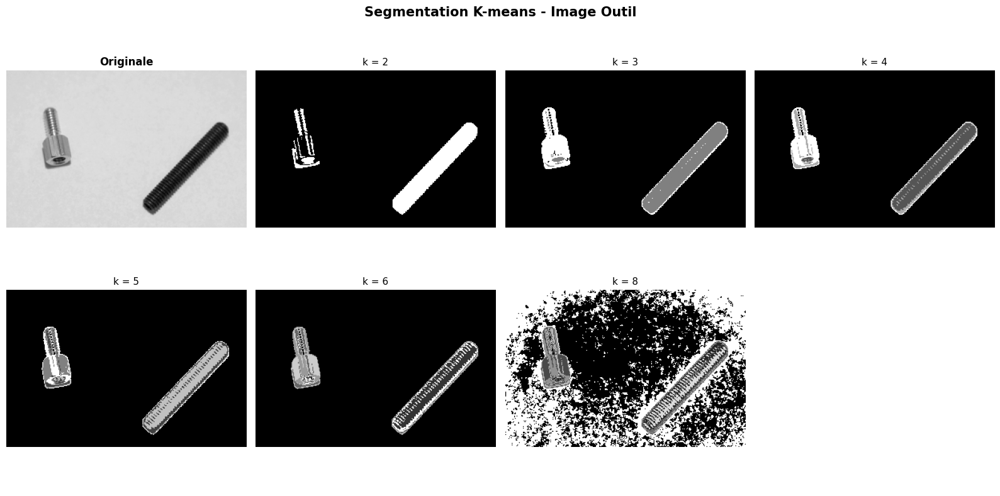

In [21]:
k_values = [2, 3, 4, 5, 6, 8]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle("Segmentation K-means - Image Outil", fontsize=15, fontweight='bold')

axes = axes.ravel()

# Image originale
axes[0].imshow(outil, cmap='gray')
axes[0].set_title("Originale", fontweight='bold')
axes[0].axis('off')

# Boucle K-means
for i, k in enumerate(k_values, start=1):

    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
    kmeans.fit(pixels)

    labels = kmeans.labels_
    segmented = labels.reshape(outil.shape)

    # normalisation pour affichage
    segmented = (segmented * (255 // (k-1))).astype(np.uint8)

    # affichage
    axes[i].imshow(segmented, cmap='gray')
    axes[i].set_title(f"k = {k}", fontsize=11)
    axes[i].axis('off')

    # affichage centres
    centers = np.sort(kmeans.cluster_centers_.flatten())
    print(f"\nK={k} → Centres: {centers}")

# désactiver cases vides
for j in range(len(k_values) + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

L’application de K-means pour différentes valeurs de k montre que la segmentation dépend fortement du nombre de clusters choisi.
Pour k=2, l’image est divisée en deux régions principales correspondant au fond et à l’objet.

Lorsque k augmente, des niveaux d’intensité supplémentaires apparaissent, permettant une segmentation plus détaillée.
Cependant, pour des valeurs élevées (k≥5), la segmentation devient moins pertinente en raison d’une sur-segmentation.

## **I.3.3. Segmentation par la méthode de croissance de région**

**1. Lire l’image *mandrillgray.bmp* et afficher la.**

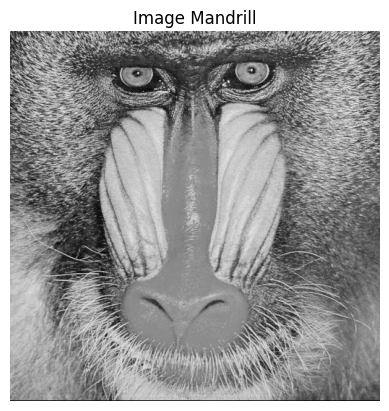

Dimensions de l'image: (512, 512)
Valeurs d'intensité: min=8, max=241, moyenne=132.94


In [22]:
plt.imshow(mandrill, cmap='gray')
plt.title("Image Mandrill")
plt.axis('off')
plt.show()
print(f"Dimensions de l'image: {mandrill.shape}")
print(f"Valeurs d'intensité: min={mandrill.min()}, max={mandrill.max()}, moyenne={mandrill.mean():.2f}")

**2. Choisir manuellement un  point germe et appliquer l'algorithme de croissance de région, pour segmenter une région avec un écart type fixé à 0.1, autour de ce germe-là**

L'objectif de cette fonction est de segmenter une région en partant d’un point germe, en ajoutant les pixels voisins similaires en intensité.

In [23]:
def region_growing(image, seed_point, threshold):

    height, width = image.shape

    # masque binaire
    mask = np.zeros((height, width), dtype=np.uint8)

    # pile des pixels à explorer
    stack = deque()
    stack.append(seed_point)

    # valeur initiale du germe
    seed_value = int(image[seed_point[1], seed_point[0]])

    # liste des pixels de la région
    region_pixels = [seed_value]

    # ajout du germe
    mask[seed_point[1], seed_point[0]] = 255

    # moyenne initiale
    region_mean = seed_value

    # voisinage 8-connecté
    directions = [(-1, -1), (-1, 0), (-1, 1),
                  (0, -1),           (0, 1),
                  (1, -1),  (1, 0),  (1, 1)]

    while stack:

        x, y = stack.popleft()

        for dx, dy in directions:

            nx, ny = x + dx, y + dy

            # vérifier limites image
            if 0 <= nx < width and 0 <= ny < height:

                # vérifier si déjà visité
                if mask[ny, nx] == 0:

                    pixel_value = int(image[ny, nx])

                    # critère de similarité
                    if abs(pixel_value - region_mean) <= threshold:

                        mask[ny, nx] = 255

                        region_pixels.append(pixel_value)

                        # mise à jour moyenne
                        region_mean = np.mean(region_pixels)

                        stack.append((nx, ny))

    return mask

Cette fonction permet à l’utilisateur de choisir manuellement un point germe en cliquant sur l’image.

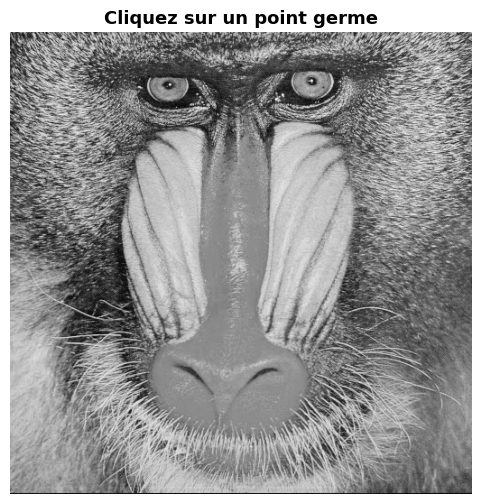

Germe par défaut : (256, 256)


In [24]:
clicked_point = None

def on_click(event):
    global clicked_point
    if event.xdata is not None and event.ydata is not None:

        clicked_point = (
            int(event.xdata),
            int(event.ydata)
        )

        print(f"Point germe sélectionné : {clicked_point}")

        plt.close()


# affichage image
fig, ax = plt.subplots(figsize=(8,6))
ax.imshow(mandrill, cmap='gray')
ax.set_title(
    "Cliquez sur un point germe",
    fontsize=13,
    fontweight='bold'
)

ax.axis('off')
fig.canvas.mpl_connect('button_press_event', on_click)
plt.show()

# si aucun clic
if clicked_point is None:

    clicked_point = (
        mandrill.shape[1] // 2,
        mandrill.shape[0] // 2
    )

    print(f"Germe par défaut : {clicked_point}")

seed = clicked_point

In [25]:
# écart-type fixé à 0.1
# image sur [0,255]
threshold = int(0.1 * 255)

# segmentation
region_mask = region_growing(
    mandrill,
    seed,
    threshold
)

print(f"Seuil utilisé : {threshold}")

Seuil utilisé : 25


**3. Afficher la région segmentée superposée à l’image initiale.**


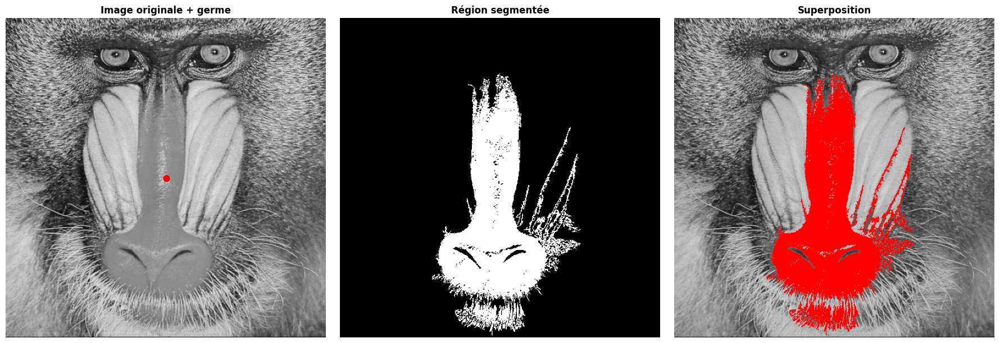

In [26]:
# conversion RGB
overlay = cv2.cvtColor(mandrill, cv2.COLOR_GRAY2RGB)

# région segmentée en rouge
overlay[region_mask == 255] = [255, 0, 0]

# affichage
fig, axes = plt.subplots(1, 3, figsize=(18,6))

# image originale
axes[0].imshow(mandrill, cmap='gray')
axes[0].plot(seed[0], seed[1], 'ro', markersize=8)
axes[0].set_title("Image originale + germe", fontweight='bold')
axes[0].axis('off')

# masque
axes[1].imshow(region_mask, cmap='gray')
axes[1].set_title("Région segmentée", fontweight='bold')
axes[1].axis('off')

# superposition
axes[2].imshow(overlay)
axes[2].set_title("Superposition", fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

Un point germe a été sélectionné manuellement sur l’image. L’algorithme de croissance de région a ensuite été appliqué en utilisant un critère basé sur l’écart-type, avec un seuil fixé à 0.1.
La région obtenue correspond à un ensemble de pixels homogènes autour du germe, présentant des intensités similaires.
Cette méthode permet de segmenter efficacement des zones cohérentes, mais le résultat dépend fortement du choix du germe et du seuil.

**4. Faire varier l’écart-type et commenter son effet sur la segmentation.**


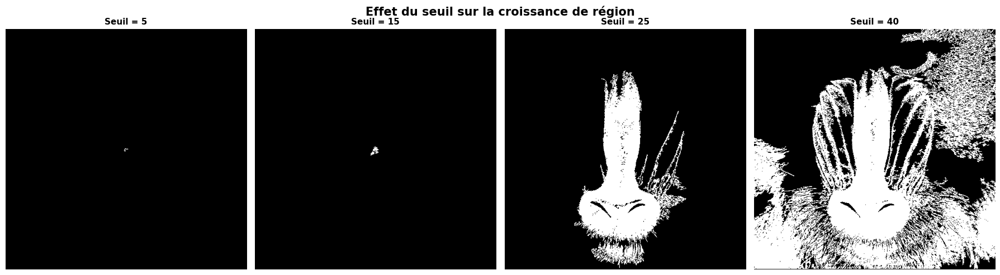

In [27]:
thresholds = [5, 15, 25, 40]
fig, axes = plt.subplots(1, 4, figsize=(18,5))
for i, t in enumerate(thresholds):

    region = region_growing(
        mandrill,
        seed,
        t
    )

    axes[i].imshow(region, cmap='gray')

    axes[i].set_title(
        f"Seuil = {t}",
        fontsize=11,
        fontweight='bold'
    )

    axes[i].axis('off')

plt.suptitle(
    "Effet du seuil sur la croissance de région",
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

Le seuil contrôle la similarité autorisée entre les pixels voisins et la région en cours de croissance.

* Un seuil faible produit une région petite et très homogène.

* Un seuil moyen permet une segmentation correcte de la zone d’intérêt.

* Un seuil élevé entraîne une expansion excessive de la région et inclut des zones non pertinentes.

Ainsi, le choix du seuil influence fortement la qualité de la segmentation.

**5. Étendre la méthode à la segmentation de 4 régions distinctes.**

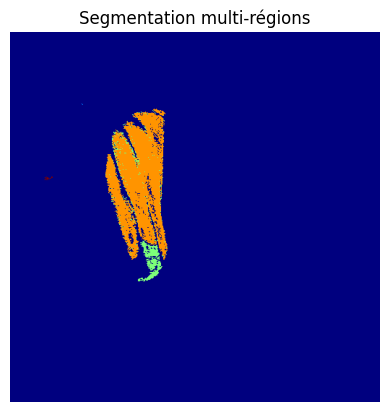

In [28]:
seeds = [(100,100), (150,150), (200,200), (50,200)]
threshold = 15

multi_region = np.zeros_like(mandrill)

for i, seed in enumerate(seeds):
    region = region_growing(mandrill, seed, threshold)
    multi_region[region == 255] = (i+1)*60  # niveaux différents

plt.imshow(multi_region, cmap='jet')
plt.title("Segmentation multi-régions")
plt.axis('off')
plt.show()

# **II- Application des méthodes de segmentation sur les images du dossier Dataset**

## **II-1  Chargement des datasets**

Charger et visualiser quelques images de chaque catégorie avec leurs grounds truth


===== Catégorie : 1objet =====


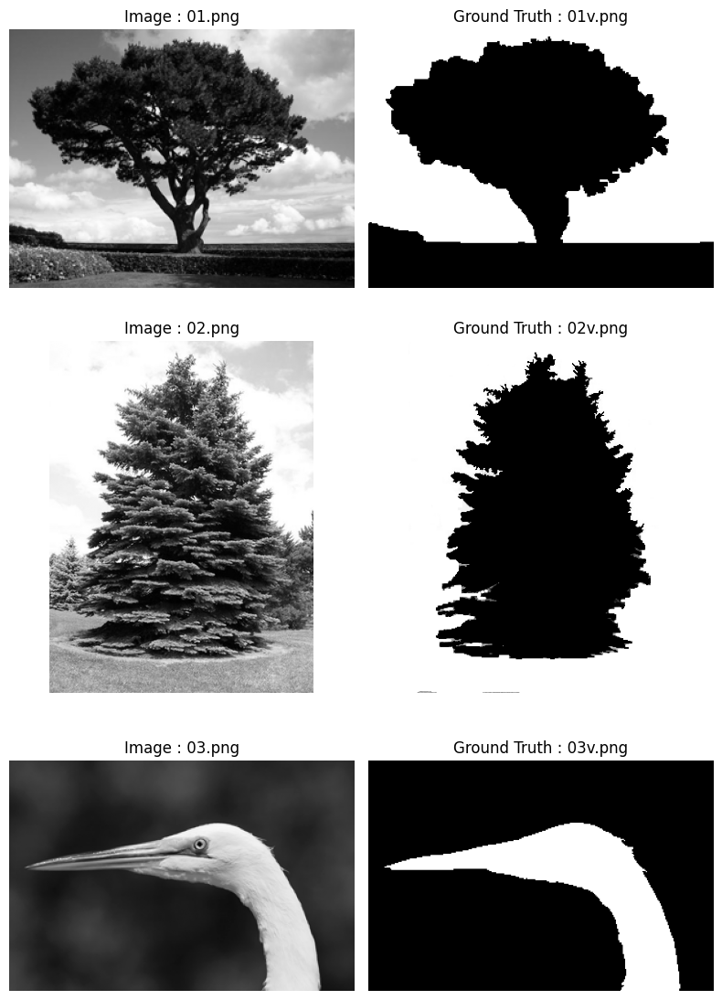


===== Catégorie : 2objets =====


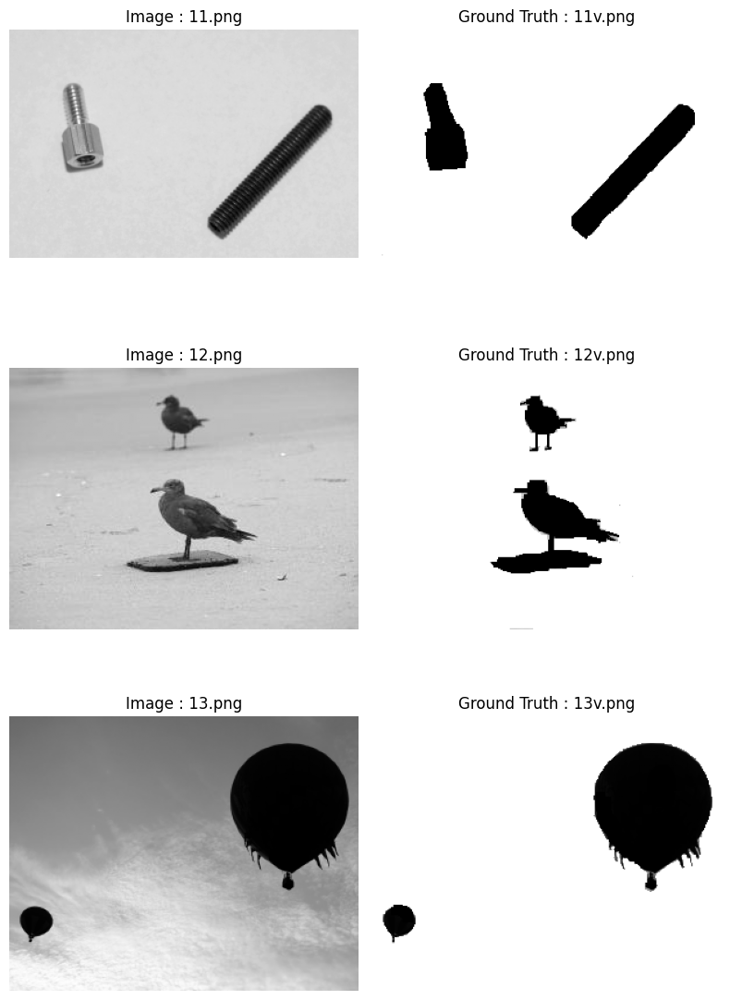


===== Catégorie : Embryons =====


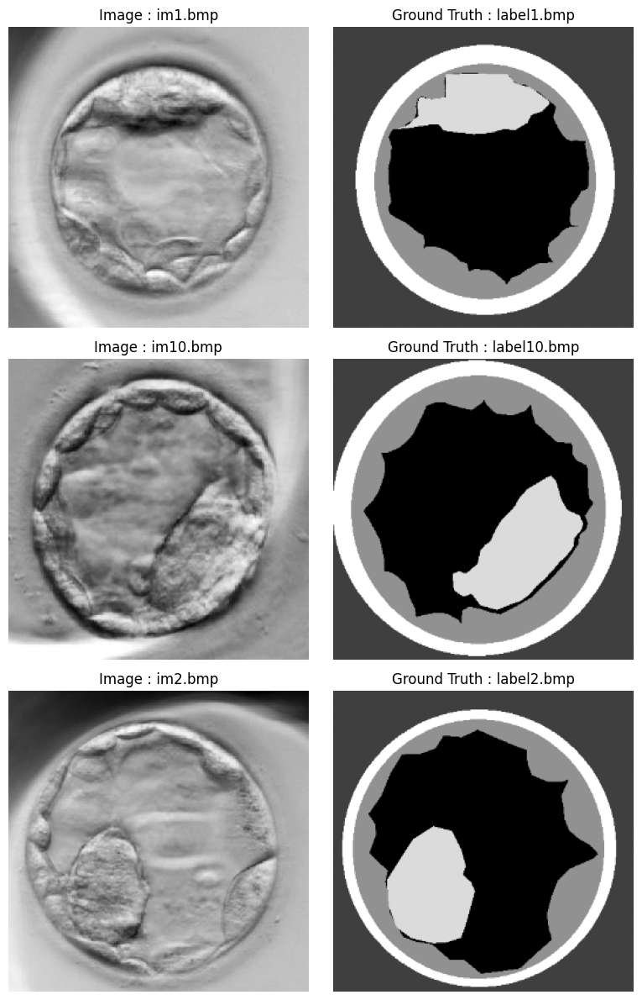


===== Catégorie : textfort =====


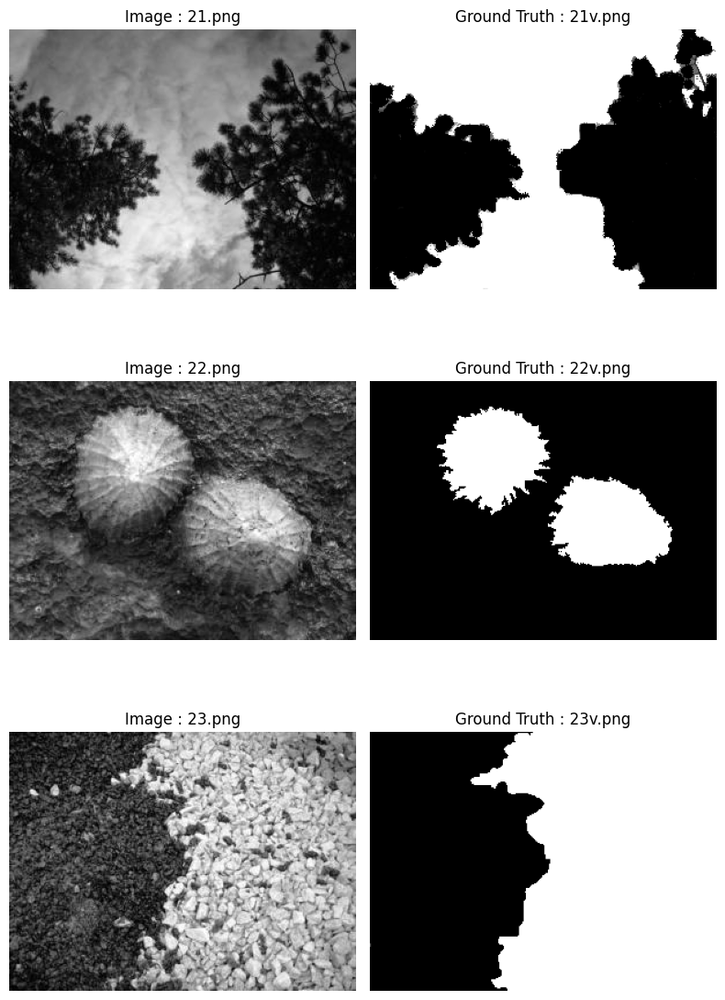

In [29]:
BASE_PATH = "/content/drive/MyDrive/Traitement d'image/Datasets"

# Dossiers des images et vérités terrain
IMAGES_PATH = os.path.join(BASE_PATH, "images")
GT_PATH = os.path.join(BASE_PATH, "verite_terrain")

# Catégories
categories = ["1objet", "2objets", "Embryons", "textfort"]

# Nombre d'images à afficher par catégorie
nb_images = 3

for category in categories:

    print(f"\n===== Catégorie : {category} =====")

    image_folder = os.path.join(IMAGES_PATH, category)
    gt_folder = os.path.join(GT_PATH, category)

    # Trier les fichiers
    image_files = sorted(os.listdir(image_folder))[:nb_images]

    # Création de la figure
    fig, axes = plt.subplots(nb_images, 2, figsize=(8, 4 * nb_images))

    # Si une seule image
    if nb_images == 1:
        axes = [axes]

    for i, img_name in enumerate(image_files):

        img_path = os.path.join(image_folder, img_name)

        # Déterminer automatiquement le nom du ground truth
        if category == "Embryons":
            number = ''.join(filter(str.isdigit, img_name))
            gt_name = f"label{number}.bmp"

        else:
            name, ext = os.path.splitext(img_name)
            gt_name = f"{name}v{ext}"

        gt_path = os.path.join(gt_folder, gt_name)

        # Charger image et GT
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)

        # Affichage image originale
        axes[i][0].imshow(img, cmap='gray')
        axes[i][0].set_title(f"Image : {img_name}")
        axes[i][0].axis("off")

        # Affichage vérité terrain
        axes[i][1].imshow(gt, cmap='gray')
        axes[i][1].set_title(f"Ground Truth : {gt_name}")
        axes[i][1].axis("off")

    plt.tight_layout()
    plt.show()

## **II-2 Prétraitement des images**

**Appliquer différents prétraitements sur chaque type d'image et observer leurs effets.**

Notre but est de tester plusieurs techniques de prétraitement afin d’améliorer la qualité des images avant la segmentation, puis comparer visuellement leurs effets.


===== Prétraitement : 1objet =====


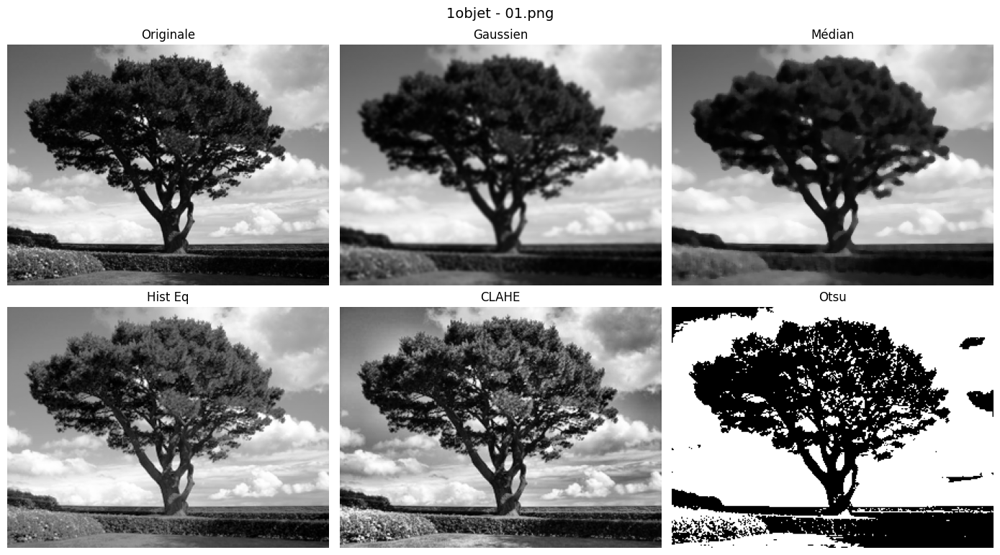

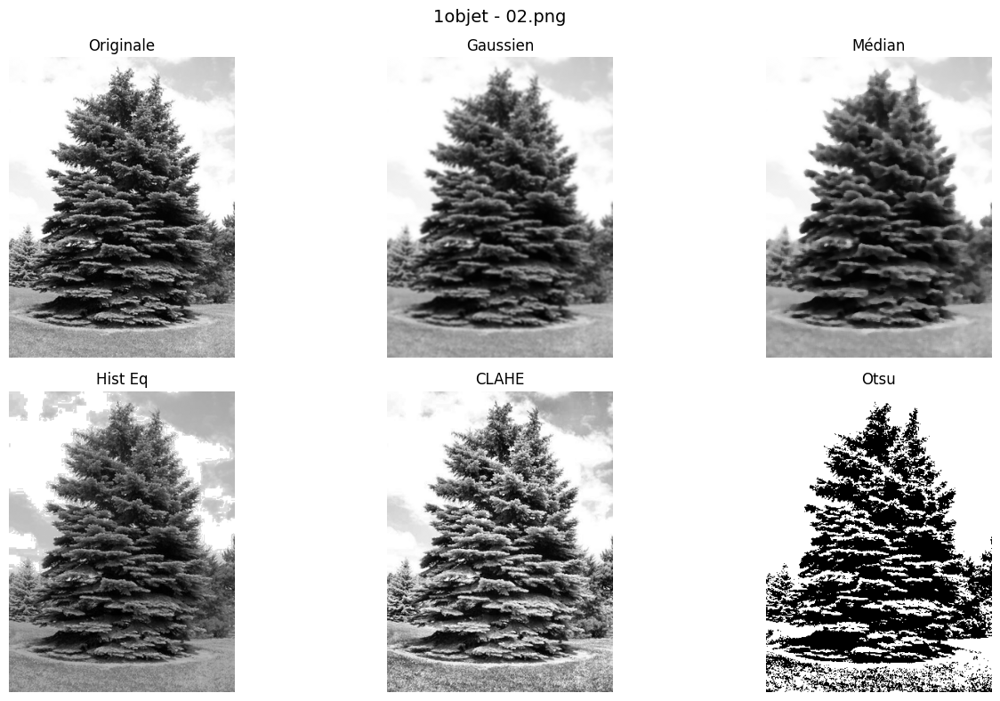


===== Prétraitement : 2objets =====


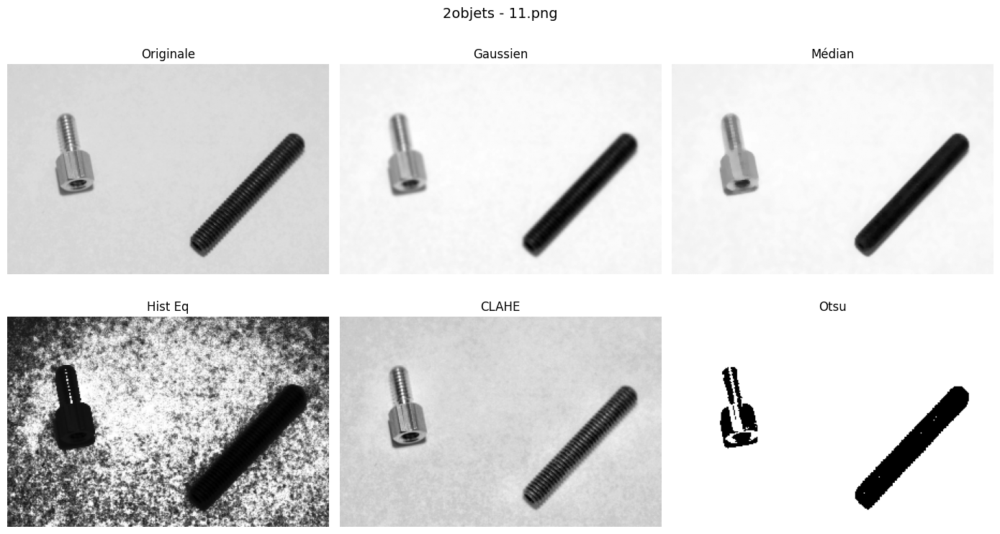

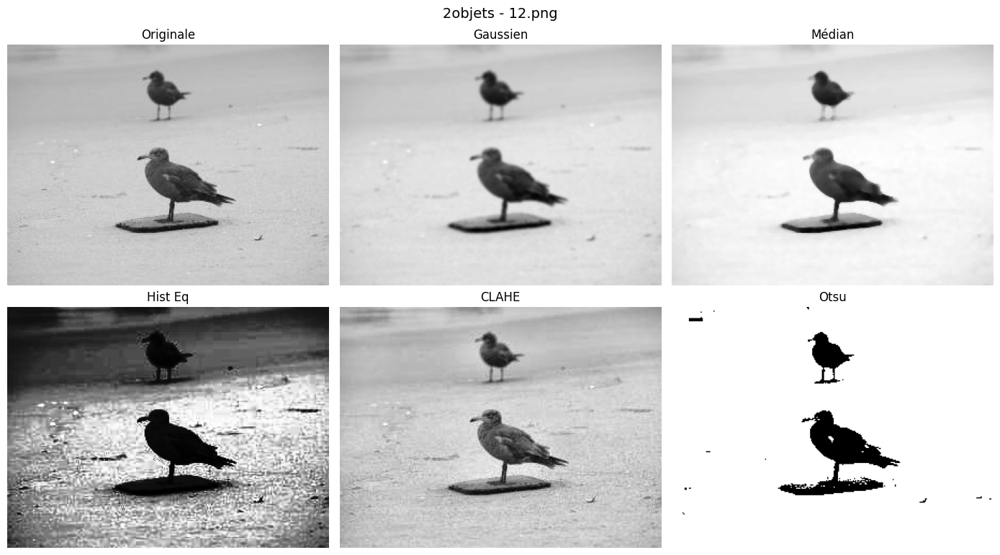


===== Prétraitement : Embryons =====


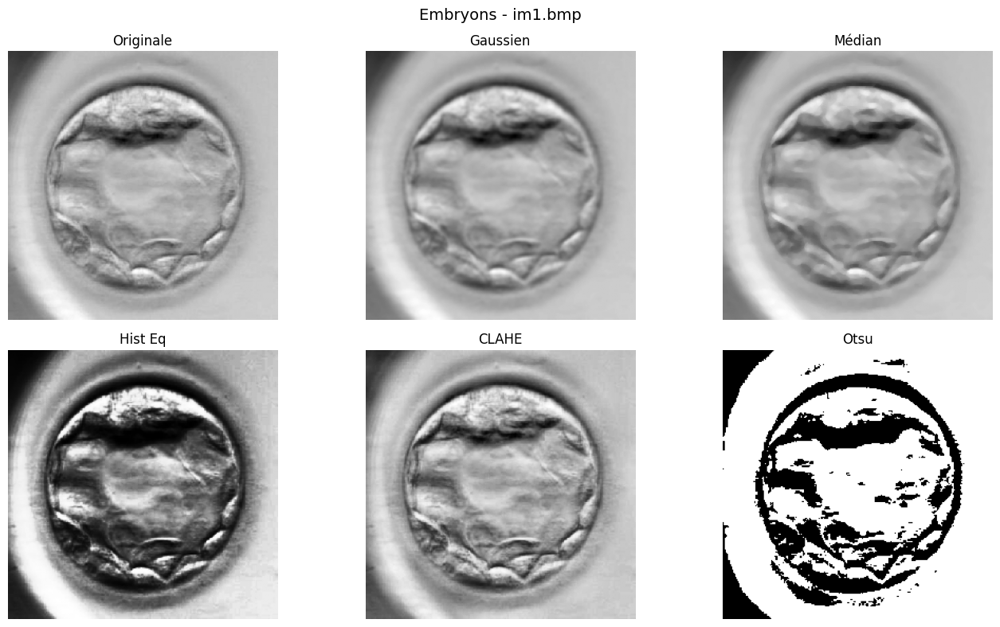

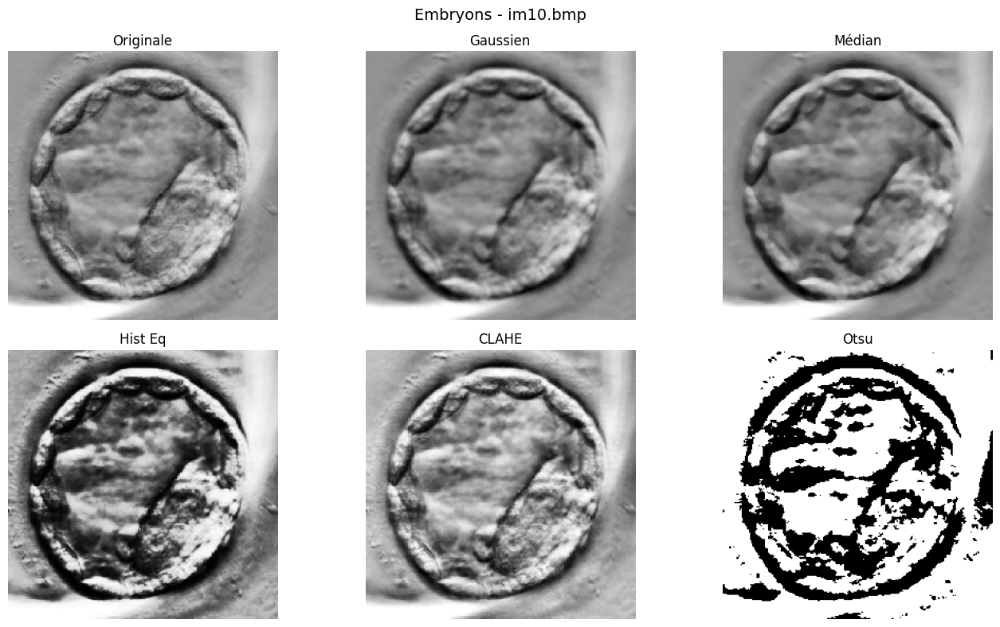


===== Prétraitement : textfort =====


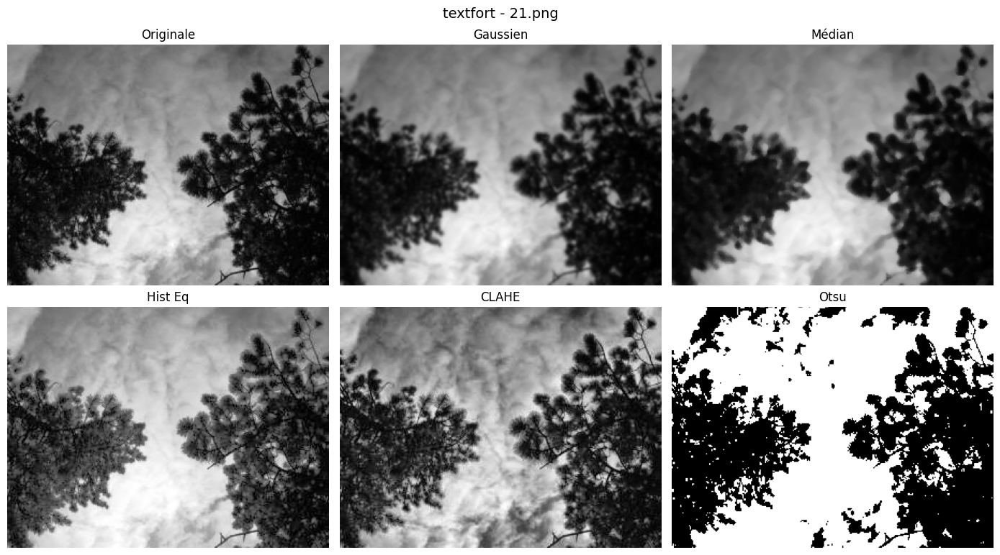

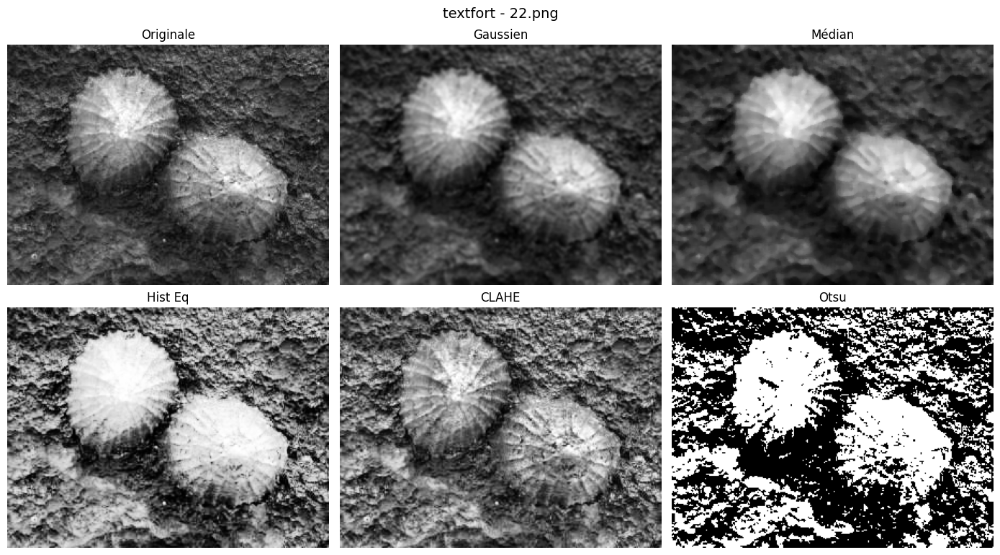

In [30]:
BASE_PATH = "/content/drive/MyDrive/Traitement d'image/Datasets/images"

# Nombre d'images à tester
nb_images = 2

for category in categories:

    print(f"\n===== Prétraitement : {category} =====")

    folder = os.path.join(BASE_PATH, category)

    image_files = sorted(os.listdir(folder))[:nb_images]

    for img_name in image_files:

        img_path = os.path.join(folder, img_name)

        # Charger image en niveaux de gris
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

        # ==============================
        # Prétraitements
        # ==============================

        # 1. Filtre Gaussien
        gaussian = cv2.GaussianBlur(img, (5, 5), 0)

        # 2. Filtre Médian
        median = cv2.medianBlur(img, 5)

        # 3. Egalisation Histogramme
        hist_eq = cv2.equalizeHist(img)

        # 4. CLAHE
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )
        clahe_img = clahe.apply(img)

        # 5. Seuillage d'Otsu
        _, otsu = cv2.threshold(
            clahe_img,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        # ==============================
        # Affichage
        # ==============================

        images = [
            img,
            gaussian,
            median,
            hist_eq,
            clahe_img,
            otsu
        ]

        titles = [
            "Originale",
            "Gaussien",
            "Médian",
            "Hist Eq",
            "CLAHE",
            "Otsu"
        ]

        plt.figure(figsize=(14, 8))

        for i in range(len(images)):

            plt.subplot(2, 3, i + 1)
            plt.imshow(images[i], cmap='gray')
            plt.title(titles[i])
            plt.axis("off")

        plt.suptitle(f"{category} - {img_name}", fontsize=14)

        plt.tight_layout()
        plt.show()

Le prétraitement influence fortement la qualité de la segmentation.
CLAHE combiné avec un filtrage et un seuillage d’Otsu donne généralement les meilleurs résultats pour les images faiblement contrastées ou bruitées.

Le filtre gaussien permet de réduire le bruit présent dans les images en appliquant un lissage global. Cependant, ce lissage entraîne également une légère perte de détails au niveau des contours des objets. Ce prétraitement reste utile avant l’étape de seuillage, car il améliore la stabilité de la segmentation.

Le filtre médian s’est montré particulièrement efficace pour éliminer le bruit impulsionnel de type salt and pepper. Contrairement au filtre gaussien, il conserve mieux les contours et les formes des objets, ce qui le rend adapté aux images contenant des détails importants.

L’égalisation d’histogramme améliore le contraste général de l’image en répartissant plus uniformément les niveaux de gris. Cette amélioration facilite la distinction entre les objets et le fond. Toutefois, dans certaines images bruitées, cette méthode peut également renforcer le bruit présent.

Le prétraitement CLAHE (Contrast Limited Adaptive Histogram Equalization) améliore le contraste de manière locale, ce qui permet de mieux faire apparaître les détails dans les zones sombres ou peu visibles. Cette méthode est particulièrement adaptée aux images médicales ou faiblement contrastées. De plus, contrairement à l’égalisation classique, CLAHE limite la surexposition et produit des résultats plus équilibrés.

Le seuillage d’Otsu permet de séparer automatiquement les objets du fond en déterminant un seuil optimal à partir de l’histogramme de l’image. Les résultats obtenus sont généralement meilleurs lorsque l’image a été préalablement améliorée par des techniques de contraste comme CLAHE ou l’égalisation d’histogramme.

## **II-3 Choix et application des méthodes de segmentation**


========== Catégorie : 1objet ==========


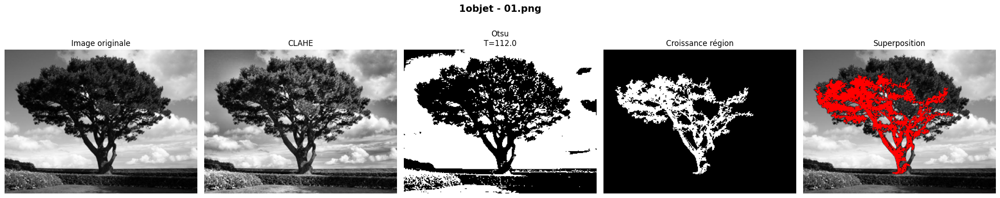

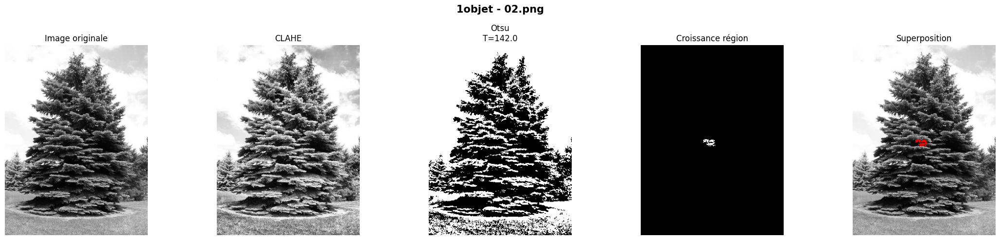


========== Catégorie : 2objets ==========


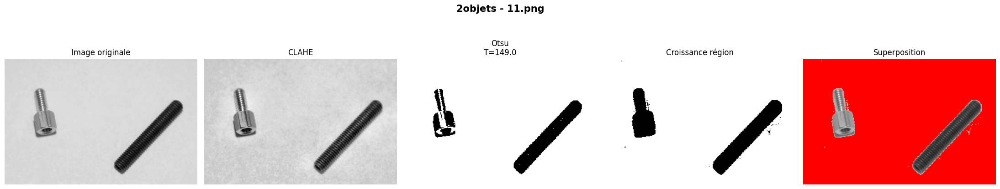

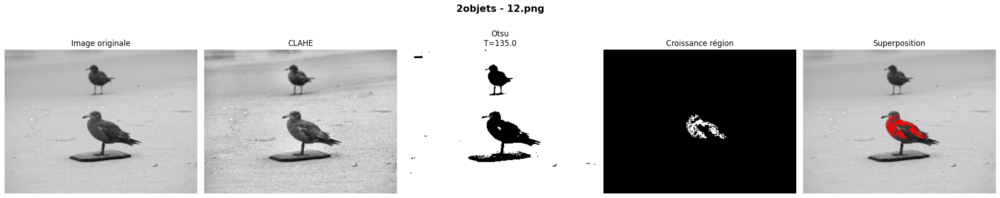


========== Catégorie : Embryons ==========


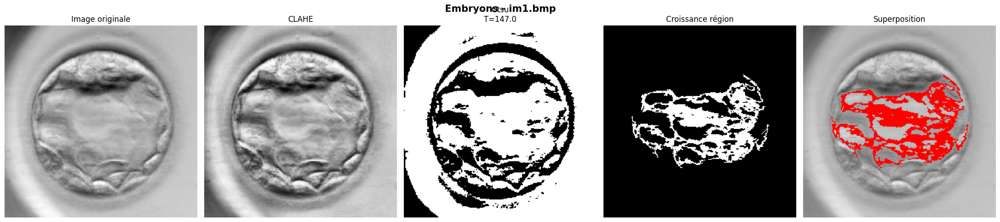

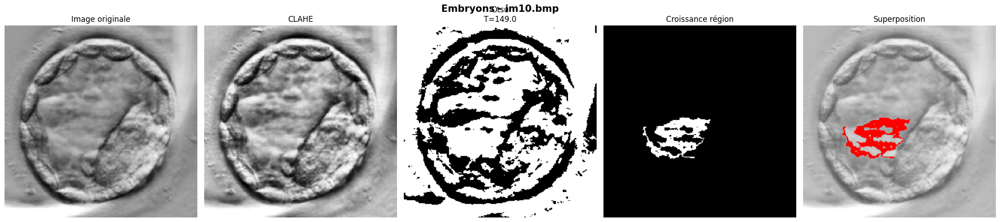


========== Catégorie : textfort ==========


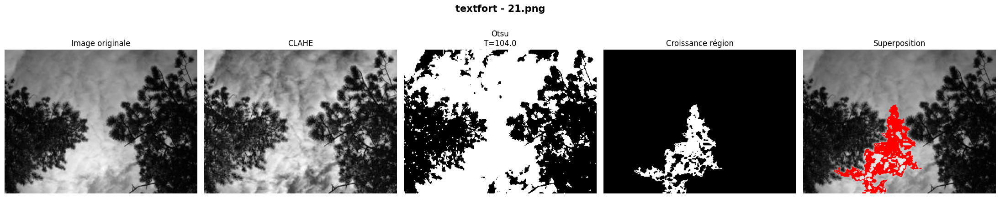

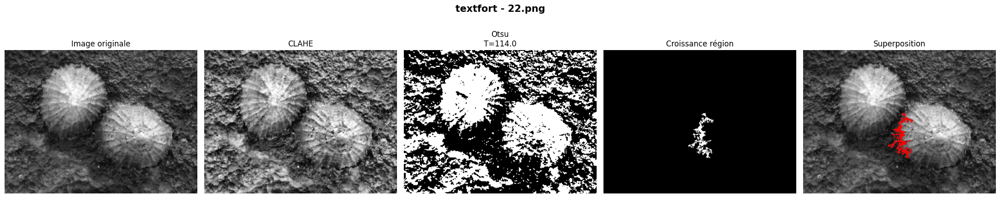

In [31]:
BASE_IMAGES = "/content/drive/MyDrive/Traitement d'image/Datasets/images"
BASE_GT = "/content/drive/MyDrive/Traitement d'image/Datasets/verite_terrain"

# FONCTION : CROISSANCE DE REGION

def region_growing(image, seed_point, threshold):

    height, width = image.shape

    mask = np.zeros((height, width), dtype=np.uint8)

    stack = deque()
    stack.append(seed_point)

    seed_value = int(image[seed_point[1], seed_point[0]])

    region_pixels = [seed_value]

    mask[seed_point[1], seed_point[0]] = 255

    region_mean = seed_value

    directions = [(-1, -1), (-1, 0), (-1, 1),
                  (0, -1),           (0, 1),
                  (1, -1),  (1, 0),  (1, 1)]

    while stack:

        x, y = stack.popleft()

        for dx, dy in directions:

            nx, ny = x + dx, y + dy

            if 0 <= nx < width and 0 <= ny < height:

                if mask[ny, nx] == 0:

                    pixel_value = int(image[ny, nx])

                    if abs(pixel_value - region_mean) <= threshold:

                        mask[ny, nx] = 255

                        region_pixels.append(pixel_value)

                        region_mean = np.mean(region_pixels)

                        stack.append((nx, ny))

    return mask

# =========================================================
# APPLICATION SUR LE DATASET
# =========================================================

# nombre d'images par catégorie
nb_images = 2

for category in categories:

    print(f"\n========== Catégorie : {category} ==========")

    image_folder = os.path.join(BASE_IMAGES, category)

    image_files = sorted(os.listdir(image_folder))[:nb_images]

    for img_name in image_files:

        # -------------------------------------------------
        # Chargement image
        # -------------------------------------------------

        img_path = os.path.join(image_folder, img_name)

        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

        # -------------------------------------------------
        # PRETRAITEMENT CLAHE
        # -------------------------------------------------

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8,8)
        )

        enhanced = clahe.apply(image)

        # -------------------------------------------------
        # SEGMENTATION OTSU
        # -------------------------------------------------

        otsu_threshold, otsu_seg = cv2.threshold(
            enhanced,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        # -------------------------------------------------
        # SEGMENTATION CROISSANCE REGION
        # -------------------------------------------------

        # germe au centre
        seed = (
            image.shape[1] // 2,
            image.shape[0] // 2
        )

        threshold_region = 20

        region_seg = region_growing(
            enhanced,
            seed,
            threshold_region
        )

        # -------------------------------------------------
        # SUPERPOSITION
        # -------------------------------------------------

        overlay = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)

        overlay[region_seg == 255] = [255, 0, 0]

        # -------------------------------------------------
        # AFFICHAGE
        # -------------------------------------------------

        fig, axes = plt.subplots(1, 5, figsize=(22,5))

        axes[0].imshow(image, cmap='gray')
        axes[0].set_title("Image originale")
        axes[0].axis('off')

        axes[1].imshow(enhanced, cmap='gray')
        axes[1].set_title("CLAHE")
        axes[1].axis('off')

        axes[2].imshow(otsu_seg, cmap='gray')
        axes[2].set_title(f"Otsu\nT={otsu_threshold:.1f}")
        axes[2].axis('off')

        axes[3].imshow(region_seg, cmap='gray')
        axes[3].set_title("Croissance région")
        axes[3].axis('off')

        axes[4].imshow(overlay)
        axes[4].set_title("Superposition")
        axes[4].axis('off')

        plt.suptitle(
            f"{category} - {img_name}",
            fontsize=15,
            fontweight='bold'
        )

        plt.tight_layout()
        plt.show()


--> Nous remarquons que la méthode de seuillage d’Otsu a fourni les meilleurs résultats parmi les techniques de segmentation testées. Contrairement au seuillage manuel, elle détermine automatiquement un seuil optimal à partir de la distribution des niveaux de gris de l’image, ce qui permet une séparation plus précise entre les objets et le fond.

Les segmentations obtenues avec Otsu présentent des régions plus homogènes et des contours mieux définis. Cette méthode réduit également les erreurs dues au choix subjectif d’un seuil manuel, ce qui améliore la robustesse et la reproductibilité des résultats sur différentes images du dataset.

## **II-4 Evaluation des performanes**

* Calculer l’indice de Jaccard et le coefficient de Dice.

* Afficher les images segmentées vs les ground truth

* Varier les prétraitements et analyser l'impact

* Calculer les moyennes par dataset et comparer les méthodes.






In [32]:
def jaccard_index(gt, pred):

    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()

    if union == 0:
        return 1.0

    return intersection / union


def dice_coefficient(gt, pred):

    intersection = np.logical_and(gt, pred).sum()

    total = gt.sum() + pred.sum()

    if total == 0:
        return 1.0

    return (2 * intersection) / total



In [33]:
def apply_preprocessing(image, method):

    if method == "original":
        return image

    elif method == "gaussian":
        return cv2.GaussianBlur(image, (5,5), 0)

    elif method == "median":
        return cv2.medianBlur(image, 5)

    elif method == "clahe":

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8,8)
        )

        return clahe.apply(image)

    else:
        return image


========== 1objet ==========
GT trouvé : 01v.png


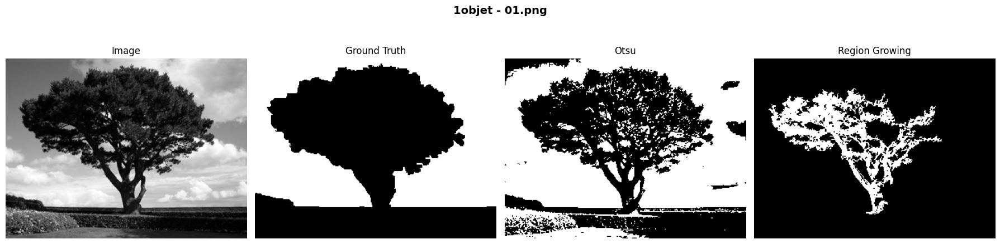

GT trouvé : 02v.png


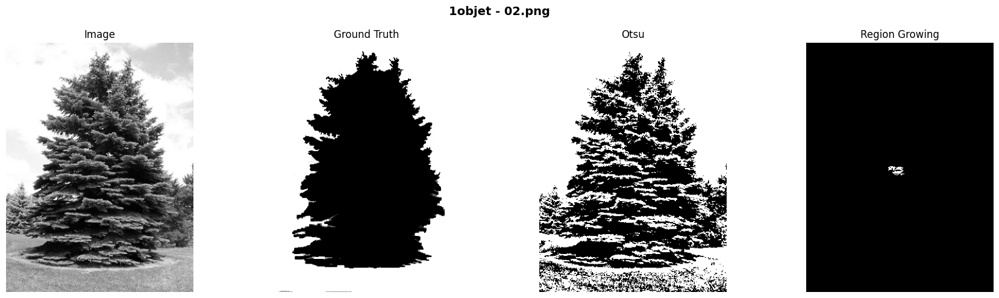

GT trouvé : 03v.png


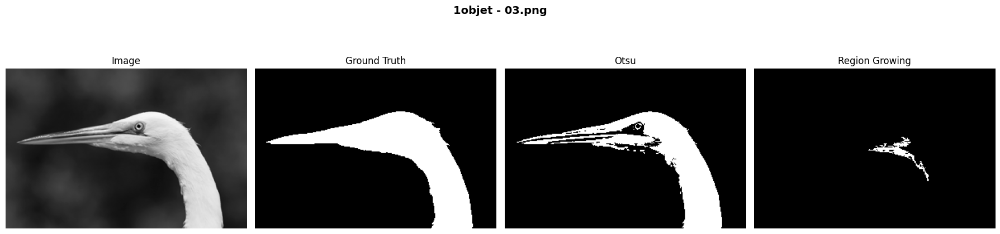

GT trouvé : 04v.png


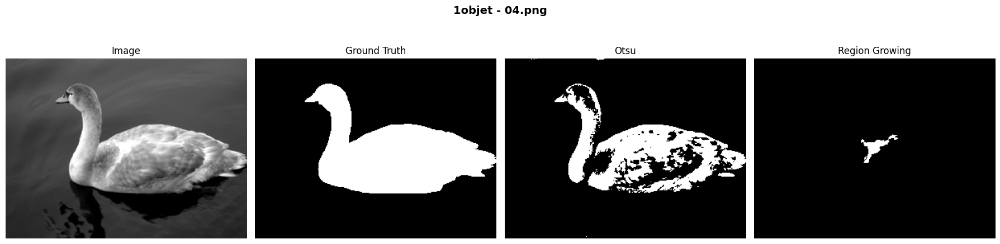

GT trouvé : 05v.png


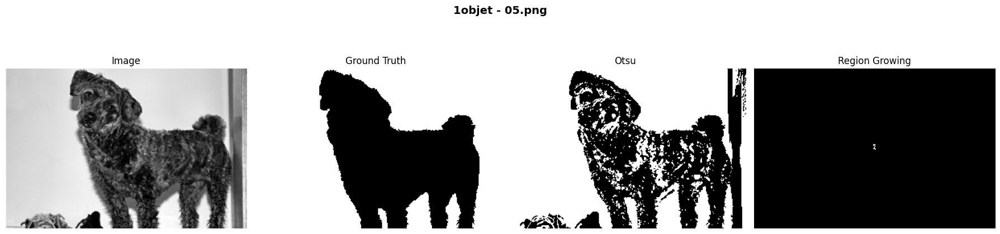

GT trouvé : 06v.png


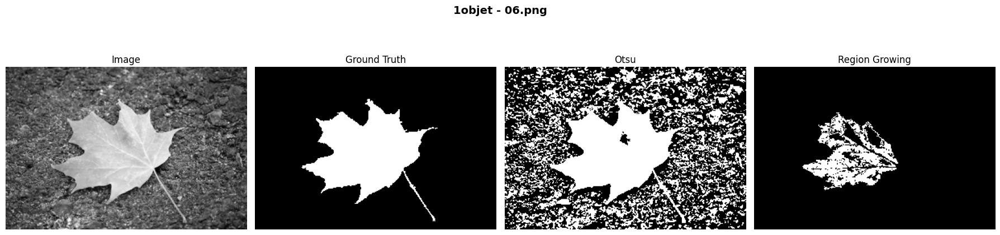

GT trouvé : 07v.png


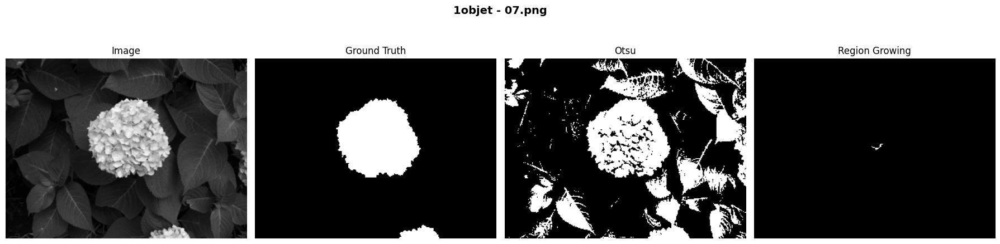

GT trouvé : 08v.png


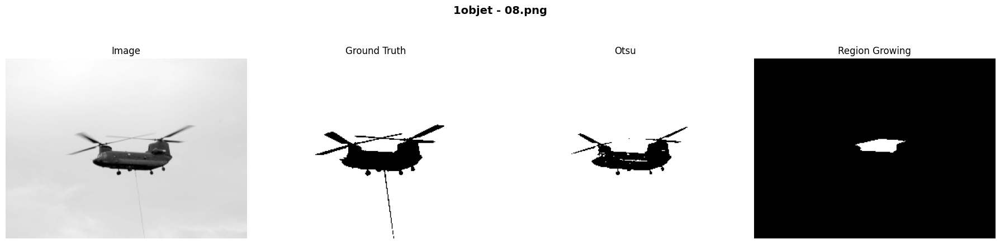

GT trouvé : 09v.png


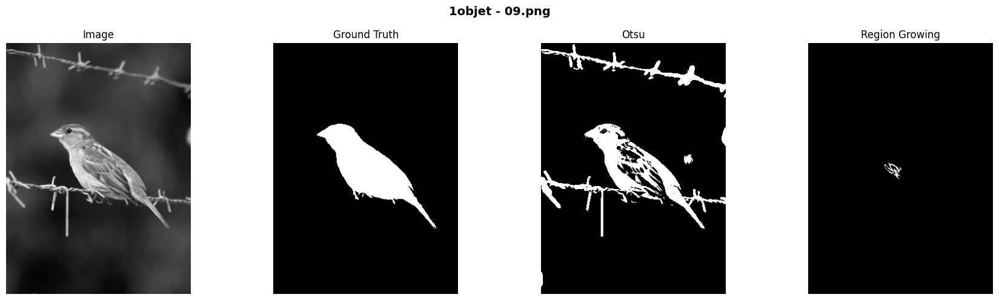

GT trouvé : 10v.png


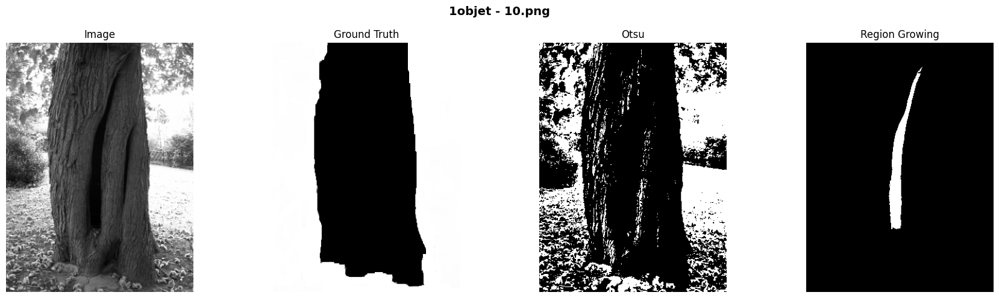


========== 2objets ==========
GT trouvé : 11v.png


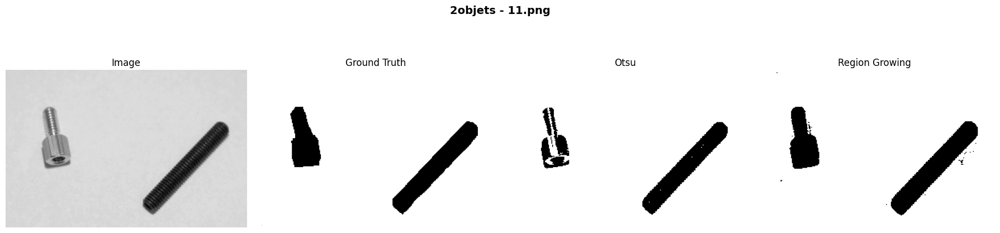

GT trouvé : 12v.png


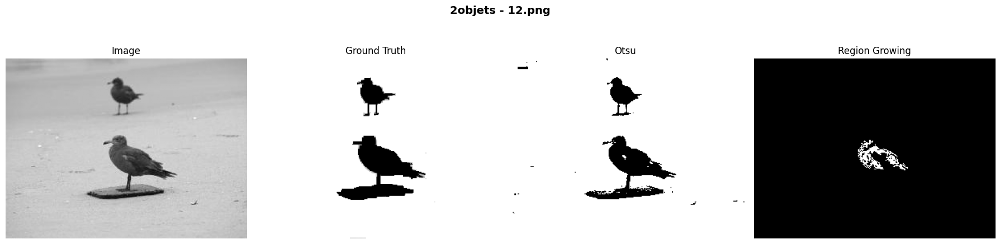

GT trouvé : 13v.png


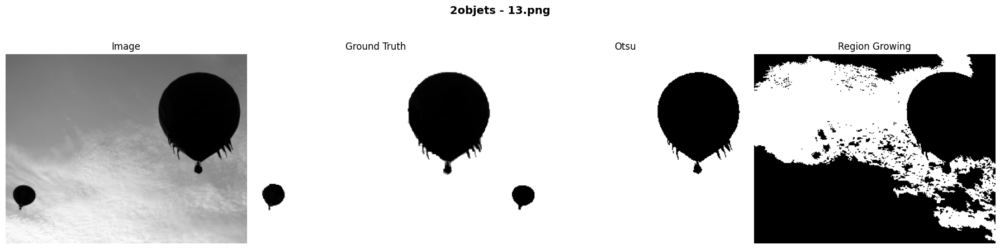

GT trouvé : 14v.png


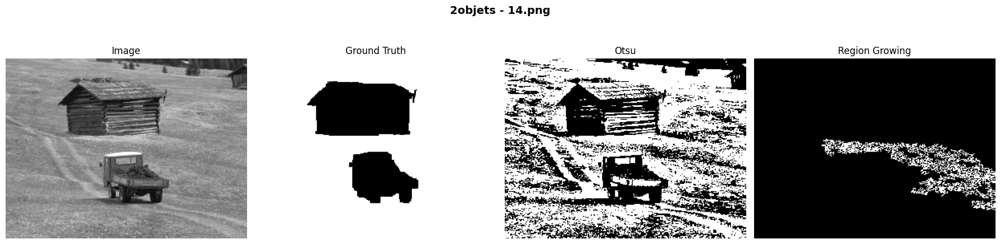

GT trouvé : 15v.png


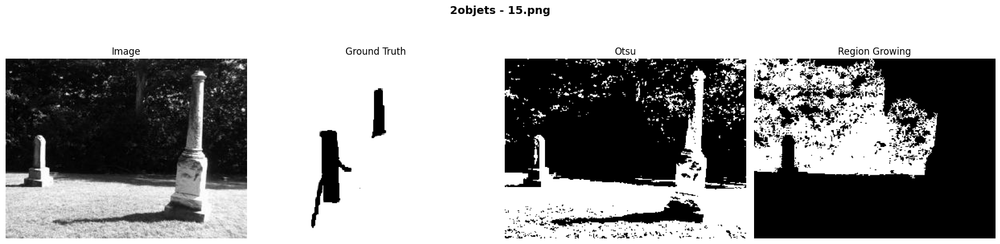

GT trouvé : 16v.png


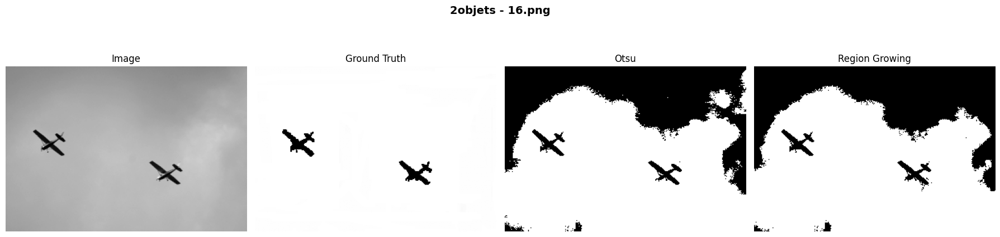

GT trouvé : 17v.png


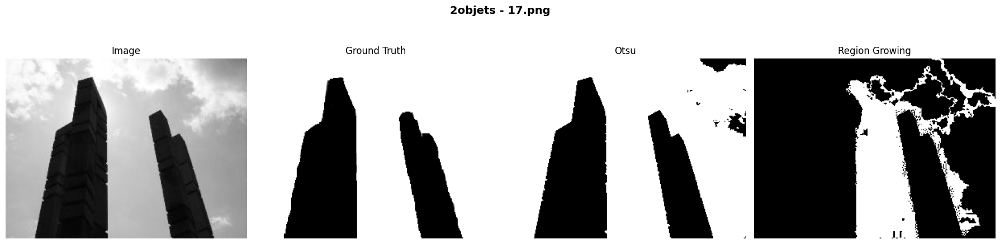

GT trouvé : 18v.png


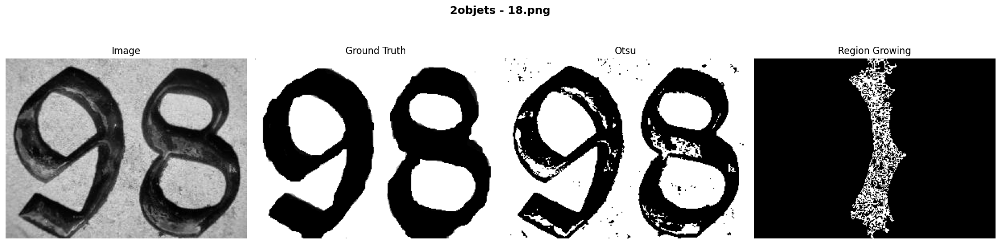

GT trouvé : 19v.png


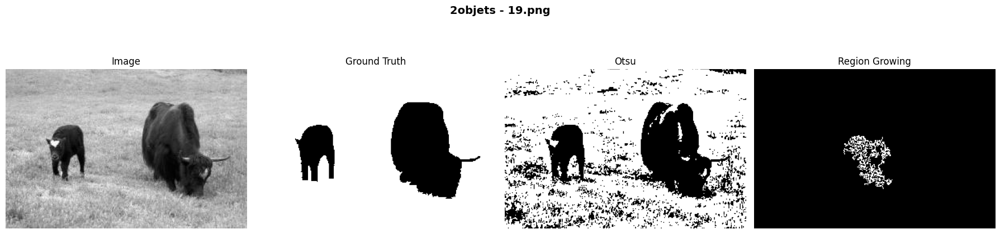

GT trouvé : 20v.png


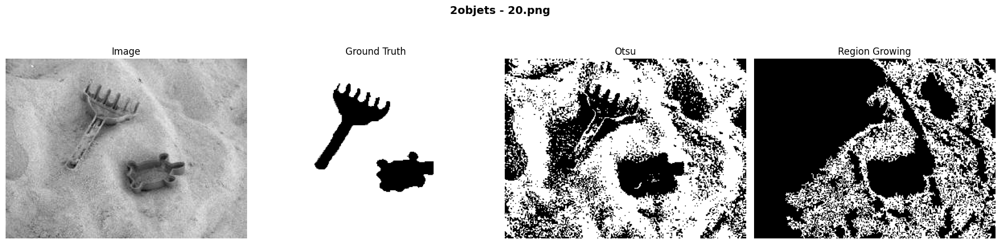


========== Embryons ==========
GT trouvé : label1.bmp


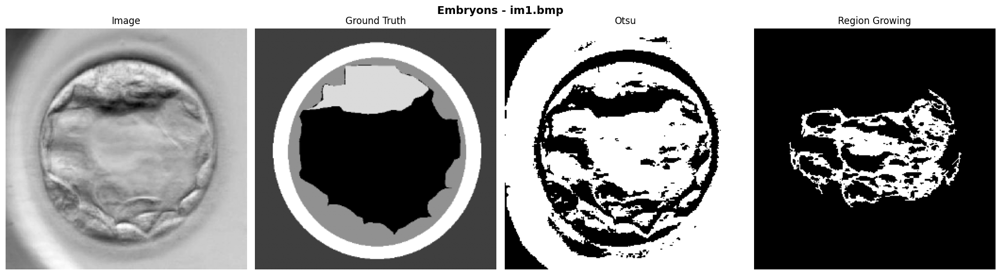

GT trouvé : label10.bmp


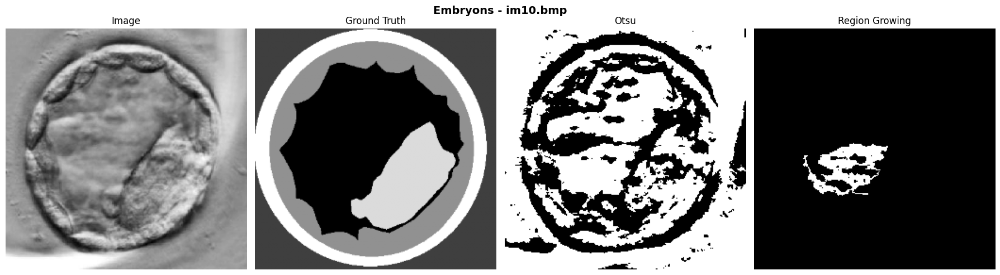

GT trouvé : label2.bmp


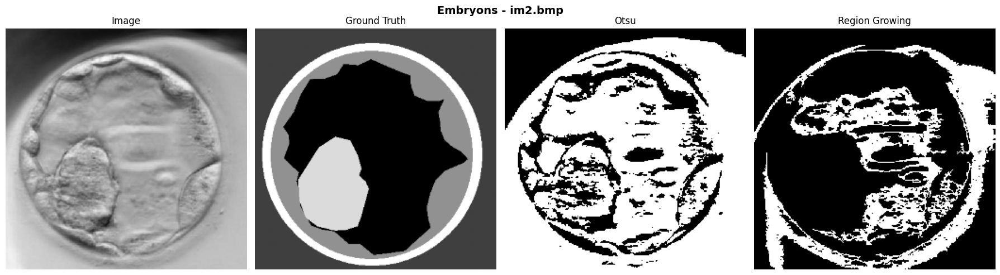

GT trouvé : label3.bmp


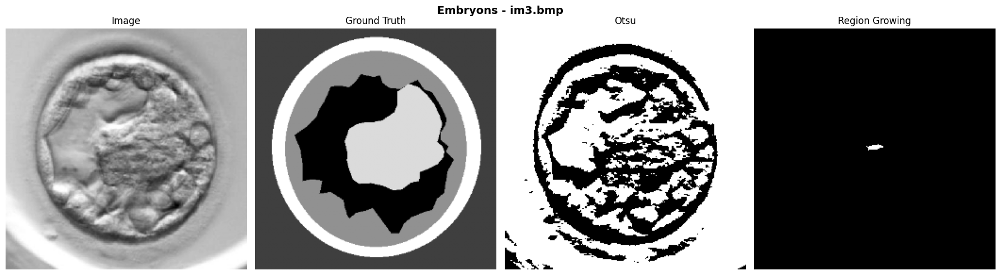

GT trouvé : label4.bmp


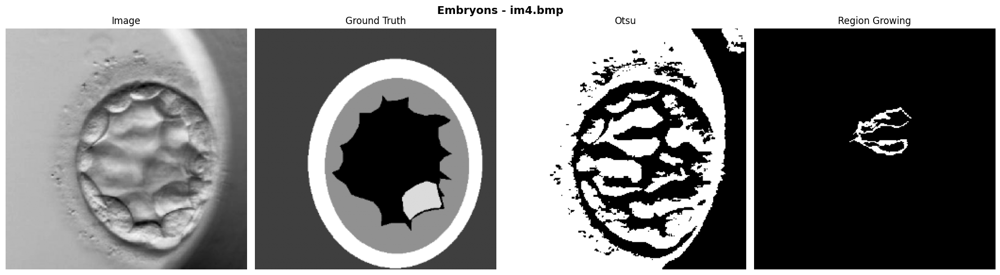

GT trouvé : label5.bmp


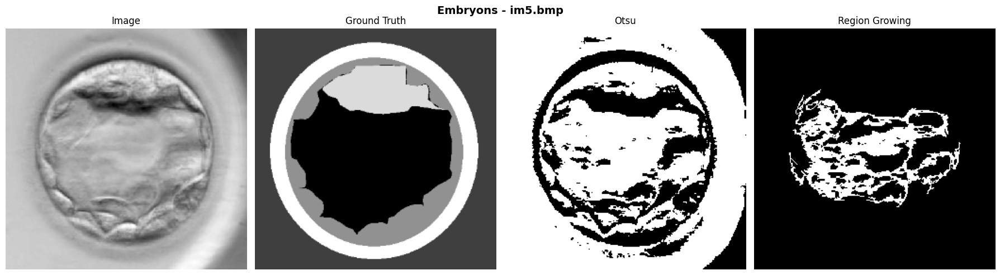

GT trouvé : label6.bmp


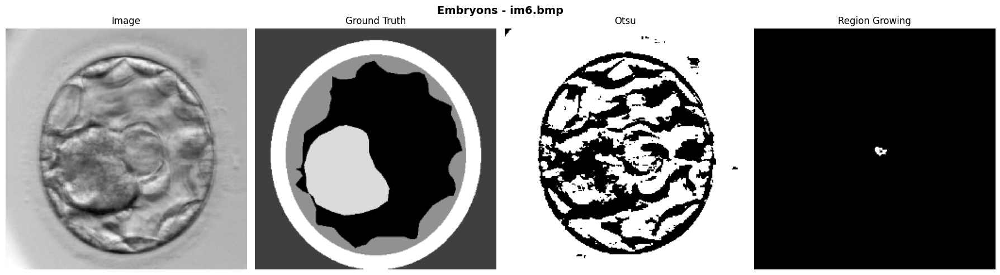

GT trouvé : label7.bmp


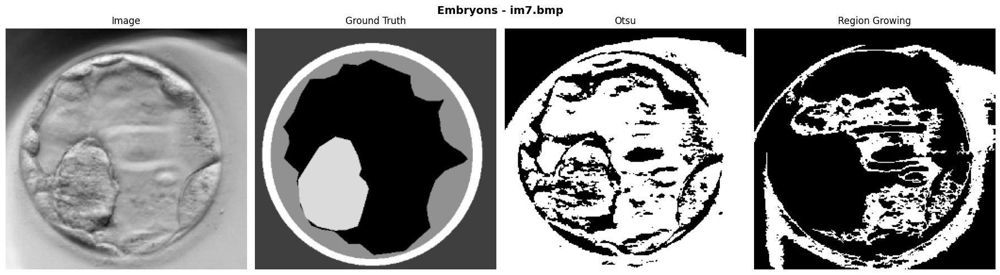

GT trouvé : label8.bmp


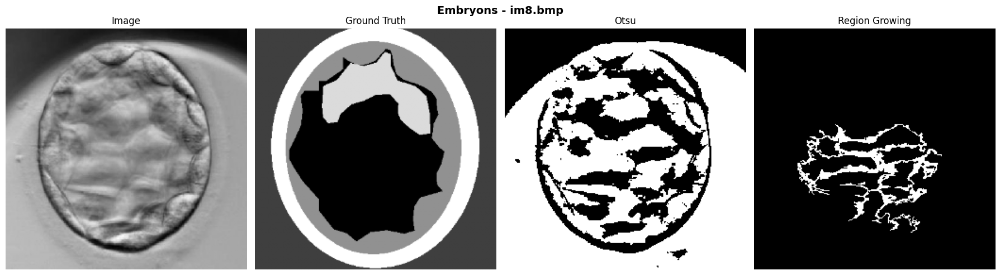

GT trouvé : label9.bmp


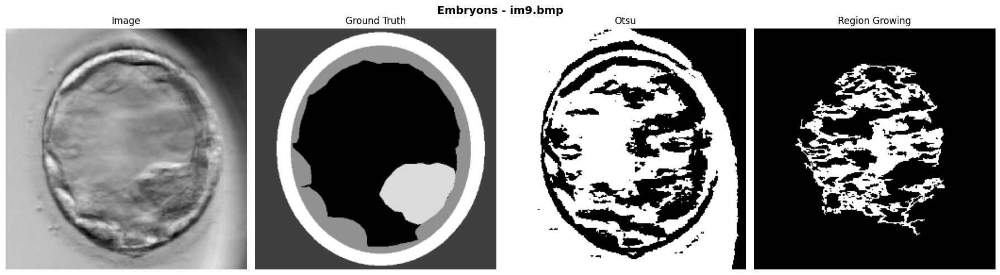


========== textfort ==========
GT trouvé : 21v.png


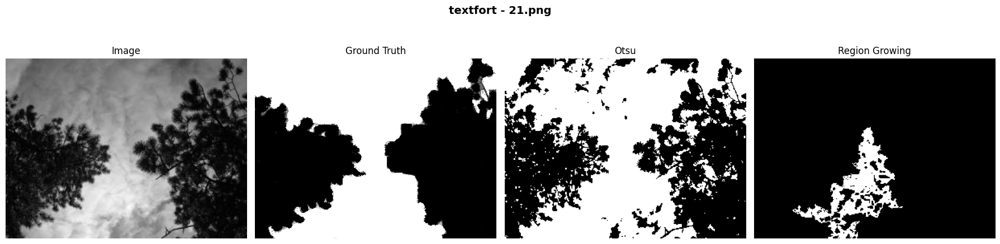

GT trouvé : 22v.png


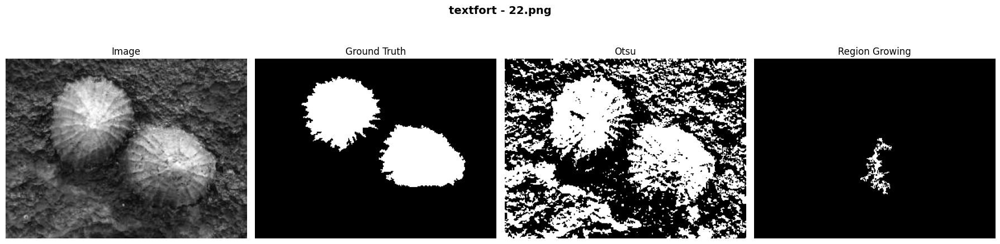

GT trouvé : 23v.png


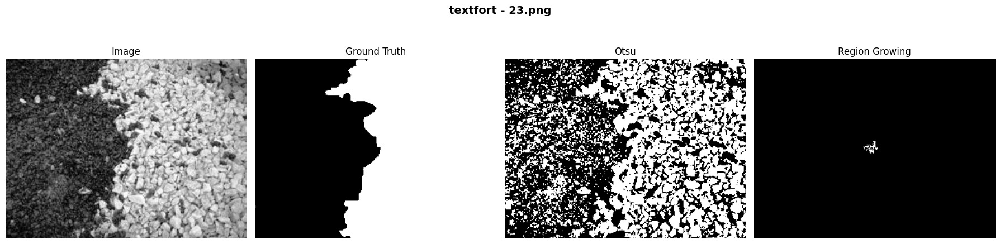

GT trouvé : 24v.png


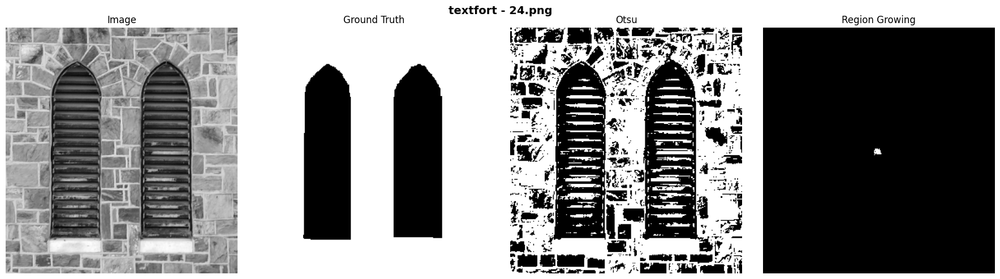

GT trouvé : 25v.png


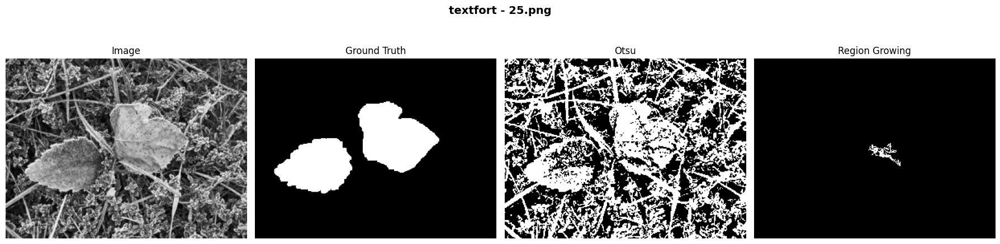

GT trouvé : 26v.png


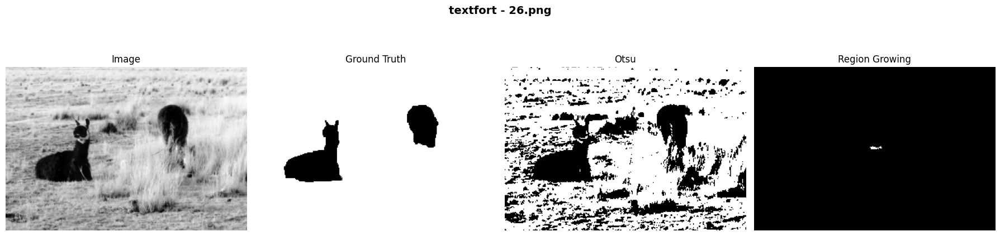

GT trouvé : 27v.jpg


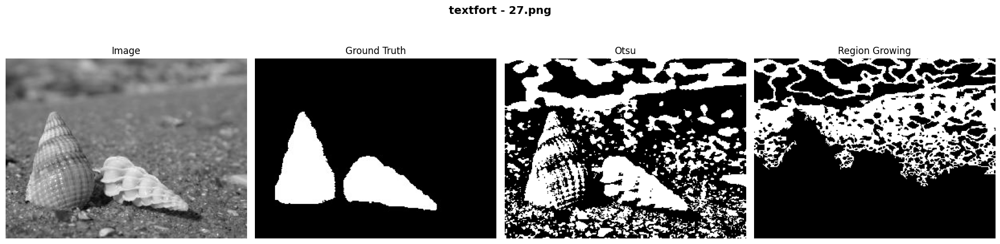

GT trouvé : 28v.png


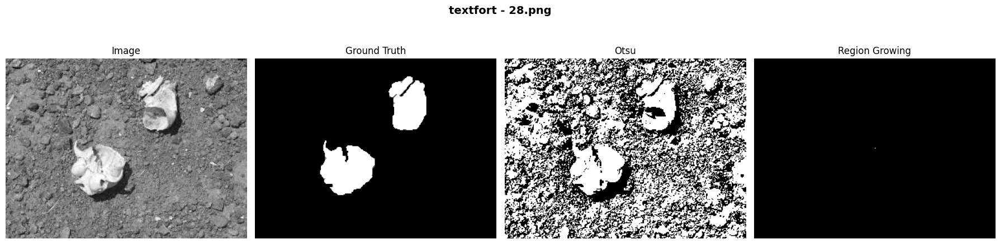

GT trouvé : 29v.png


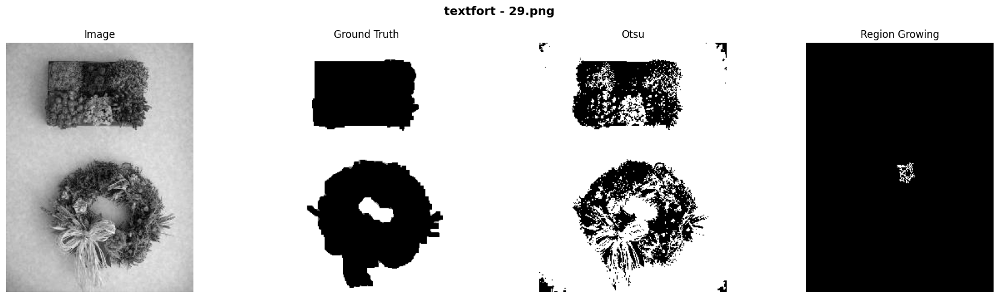

GT trouvé : 30v.png


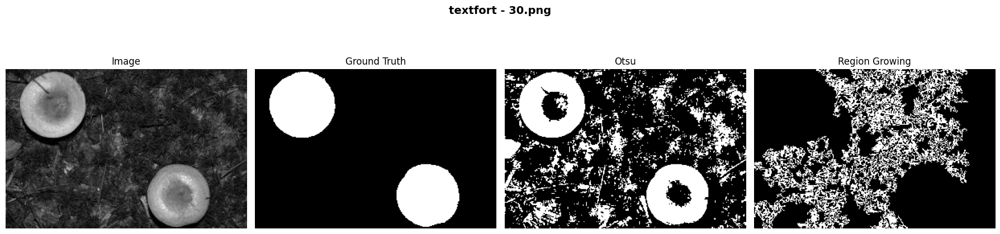

In [34]:
# LISTE DES PRETRAITEMENTS
preprocessing_methods = [
    "original",
    "gaussian",
    "median",
    "clahe"
]

# STOCKAGE RESULTATS
results = []

# BOUCLE PRINCIPALE
for category in categories:

    print(f"\n========== {category} ==========")

    image_folder = os.path.join(BASE_IMAGES, category)
    gt_folder = os.path.join(BASE_GT, category)

    image_files = sorted(os.listdir(image_folder))

    for img_name in image_files:

        # IMAGE
        img_path = os.path.join(image_folder, img_name)

        image = cv2.imread(
            img_path,
            cv2.IMREAD_GRAYSCALE
        )

        # GROUND TRUTH
        if category == "Embryons":

            number = ''.join(filter(str.isdigit, img_name))

            possible_gt = [
                f"label{number}.bmp"
            ]

        else:

            name, _ = os.path.splitext(img_name)

            possible_gt = [
                f"{name}v.png",
                f"{name}v.jpg",
                f"{name}v.bmp"
            ]

        gt = None

        for gt_file in possible_gt:

            gt_path = os.path.join(gt_folder, gt_file)

            if os.path.exists(gt_path):

                gt = cv2.imread(
                    gt_path,
                    cv2.IMREAD_GRAYSCALE
                )

                print(f"GT trouvé : {gt_file}")

                break

        # Vérification
        if gt is None:

            print(f"Ground truth introuvable pour {img_name}")
            continue

        # =================================================
        # REDIMENSIONNEMENT SI NECESSAIRE
        # =================================================

        if gt.shape != image.shape:

            gt = cv2.resize(
                gt,
                (image.shape[1], image.shape[0]),
                interpolation=cv2.INTER_NEAREST
            )
        # binarisation GT
        gt_binary = (gt > 127).astype(np.uint8)

        # TEST DES PRETRAITEMENTS
        for prep in preprocessing_methods:
            processed = apply_preprocessing(
                image,
                prep
            )

            # ---------------------------------------------
            # SEGMENTATION OTSU
            # ---------------------------------------------

            _, otsu_seg = cv2.threshold(
                processed,
                0,
                255,
                cv2.THRESH_BINARY + cv2.THRESH_OTSU
            )

            otsu_binary = (otsu_seg > 127).astype(np.uint8)

            # ---------------------------------------------
            # SEGMENTATION REGION GROWING
            # ---------------------------------------------

            seed = (
                image.shape[1] // 2,
                image.shape[0] // 2
            )

            region_seg = region_growing(
                processed,
                seed,
                threshold=20
            )

            region_binary = (
                region_seg > 127
            ).astype(np.uint8)

            # ---------------------------------------------
            # METRIQUES OTSU
            # ---------------------------------------------

            jaccard_otsu = jaccard_index(
                gt_binary,
                otsu_binary
            )

            dice_otsu = dice_coefficient(
                gt_binary,
                otsu_binary
            )

            # ---------------------------------------------
            # METRIQUES REGION GROWING
            # ---------------------------------------------

            jaccard_region = jaccard_index(
                gt_binary,
                region_binary
            )

            dice_region = dice_coefficient(
                gt_binary,
                region_binary
            )

            # ---------------------------------------------
            # sauvegarde résultats
            # ---------------------------------------------

            results.append([
                category,
                img_name,
                prep,
                "Otsu",
                jaccard_otsu,
                dice_otsu
            ])

            results.append([
                category,
                img_name,
                prep,
                "RegionGrowing",
                jaccard_region,
                dice_region
            ])

        # AFFICHAGE COMPARAISON
        fig, axes = plt.subplots(1,4, figsize=(18,5))

        axes[0].imshow(image, cmap='gray')
        axes[0].set_title("Image")
        axes[0].axis('off')

        axes[1].imshow(gt, cmap='gray')
        axes[1].set_title("Ground Truth")
        axes[1].axis('off')

        axes[2].imshow(otsu_seg, cmap='gray')
        axes[2].set_title("Otsu")
        axes[2].axis('off')

        axes[3].imshow(region_seg, cmap='gray')
        axes[3].set_title("Region Growing")
        axes[3].axis('off')

        plt.suptitle(
            f"{category} - {img_name}",
            fontsize=14,
            fontweight='bold'
        )

        plt.tight_layout()
        plt.show()



# **Conculsion :**
Résumer les meilleures combinaisons méthode + prétraitement pour chaque type d'images. Commenter les performances globales.


In [35]:
# DATAFRAME RESULTATS
df = pd.DataFrame(results, columns=[
    "Dataset",
    "Image",
    "Preprocessing",
    "Method",
    "Jaccard",
    "Dice"
])

# MOYENNES PAR DATASET

mean_results = df.groupby([
    "Dataset",
    "Preprocessing",
    "Method"
])[["Jaccard", "Dice"]].mean()

print("\n========== MOYENNES ==========\n")

print(mean_results)

# COMPARAISON GLOBALE
global_results = df.groupby([
    "Method",
    "Preprocessing"
])[["Jaccard", "Dice"]].mean()

print("\n========== RESULTATS GLOBAUX ==========\n")

print(global_results)


========== MOYENNES ==========

                                       Jaccard      Dice
Dataset  Preprocessing Method                           
1objet   clahe         Otsu           0.636438  0.760553
                       RegionGrowing  0.051623  0.078974
         gaussian      Otsu           0.819375  0.895542
                       RegionGrowing  0.283723  0.345975
         median        Otsu           0.815373  0.892654
                       RegionGrowing  0.288835  0.349753
         original      Otsu           0.791559  0.878205
                       RegionGrowing  0.246954  0.299434
2objets  clahe         Otsu           0.796198  0.870284
                       RegionGrowing  0.322527  0.417615
         gaussian      Otsu           0.873741  0.916640
                       RegionGrowing  0.593579  0.689912
         median        Otsu           0.873276  0.916146
                       RegionGrowing  0.601660  0.696327
         original      Otsu           0.892239  0.92726

Les résultats montrent que la méthode de seuillage d’Otsu est globalement la plus performante sur tous les datasets. Elle obtient les meilleurs scores de Jaccard et de Dice, ce qui indique une bonne correspondance entre les segmentations produites et les ground truth.

Les meilleurs résultats sont obtenus avec les prétraitements par filtre médian et filtre gaussien. Ces deux méthodes réduisent le bruit et améliorent la qualité de la segmentation, notamment pour les datasets 1objet, 2objets et textfort.

Le dataset 2objets présente les meilleures performances globales, avec des coefficients de Dice dépassant 0.92 pour Otsu. Cela montre que les objets sont bien distingués du fond. À l’inverse, le dataset Embryons donne les résultats les plus faibles à cause de la complexité des images et du faible contraste.

La méthode de croissance de région donne des performances plus faibles dans tous les cas. Ses résultats dépendent fortement du choix du point germe et du seuil de similarité, ce qui la rend moins robuste que le seuillage d’Otsu.

En conclusion, le seuillage d’Otsu combiné à un prétraitement médian ou gaussien constitue la méthode la plus efficace pour ce dataset.